# Práctica de clasificación · Reservas y reseñas de hotel

Proyecto de Ciencia de Datos. Datos sintéticos de reservas y reseñas de un hotel: los tres archivos son independientes y no se unen.

## 0. Entorno

El notebook es autoejecutable: se puede reproducir entero de principio a fin con *Restart & Run All*. Los CSV se leen con rutas relativas (deben estar en la misma carpeta) y todas las semillas son fijas.

Instalación de las librerías necesarias (solo hace falta la primera vez):

In [1]:
%pip install -q numpy pandas scikit-learn imbalanced-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


Imports comunes a toda la práctica y semilla:

In [2]:
# Imports comunes para toda la práctica
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imblearn
from IPython.display import display

# scikit-learn: partición, validación y búsqueda de hiperparámetros
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, KFold,
    cross_validate, cross_val_predict, GridSearchCV,
)
# scikit-learn: pipeline, preprocesamiento y modelos
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.multiclass import OneVsRestClassifier
# scikit-learn: métricas
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, precision_recall_curve, auc, roc_auc_score, average_precision_score,
    classification_report, make_scorer, hamming_loss,
)

# imblearn: pipeline con remuestreo y samplers
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.over_sampling import RandomOverSampler, SMOTE, SMOTENC

# Semilla común para toda la práctica
SEED = 42

Versiones del entorno utilizadas:

In [3]:
# Versiones del entorno
import sys
import matplotlib
import sklearn

print("Python:      ", sys.version.split()[0])
print("numpy:       ", np.__version__)
print("pandas:      ", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("imblearn:    ", imblearn.__version__)
print("matplotlib:  ", matplotlib.__version__)

Python:       3.13.18
numpy:        2.5.5
pandas:       3.1.1
scikit-learn: 1.9.1
imblearn:     0.14.2
matplotlib:   3.11.2


## 1. Ejercicio 1 · Las reservas que se quedan vacías

Objetivo: predecir qué reservas no se presentarán, para que el hotel priorice las llamadas de confirmación sin contactar innecesariamente con demasiados clientes.

Datos: 01_reservas_hotel.csv, con el historial de reservas del hotel y un atributo que indica si el cliente asistió o no a su estancia. Ese atributo, no_presentado, es la clase: 1 = no se presenta (clase positiva) y 0 = se presenta.

### 1.0 Preparación

Exploración de los datos y preparación previa a la comparación de modelos.

#### Lectura y estructura

Se lee el archivo, se comprueba que tiene el tamaño esperado según el diccionario (6.000 filas y 12 columnas) y se separan los roles de cada columna: el identificador y el objetivo quedan fuera de los predictores.

In [4]:
d = pd.read_csv("data/01_reservas_hotel.csv")
print(f"Filas: {d.shape[0]}  |  Columnas: {d.shape[1]}")
display(d.head())

Filas: 6000  |  Columnas: 12


,id_reserva,antelacion_dias,noches,huespedes,precio_noche_eur,reservas_previas,ausencias_previas,cambios_reserva,solicitudes_especiales,deposito_pagado,llegada_fin_semana,no_presentado
0,R00000,9,5,2,133.57,2,0,1,0,1,1,0
1,R00001,8,4,3,61.00,0,0,0,0,0,1,0
2,R00002,20,2,2,74.78,3,0,1,1,1,1,0
3,R00003,23,4,3,106.67,2,0,3,0,1,0,0
4,R00004,27,2,1,131.65,3,0,0,0,1,1,0


In [5]:
# Roles: id_reserva (identificador) y no_presentado (objetivo) no entran en X
X = d.drop(columns=["id_reserva", "no_presentado"])
y = d["no_presentado"]
print(f"Predictores: {X.shape[1]}")
print("\nTipos de datos:")
print(d.dtypes)

Predictores: 10

Tipos de datos:
id_reserva                    str
antelacion_dias             int64
noches                      int64
huespedes                   int64
precio_noche_eur          float64
reservas_previas            int64
ausencias_previas           int64
cambios_reserva             int64
solicitudes_especiales      int64
deposito_pagado             int64
llegada_fin_semana          int64
no_presentado               int64
dtype: object


#### Tipos de variable

El número de valores distintos de cada predictor permite distinguir binarias (2 valores), discretas (pocos enteros) y continuas. Esta clasificación se usa después para el análisis y para tratar las variables binarias en el remuestreo.

In [6]:
display(X.nunique().sort_values().rename("valores distintos").to_frame())

,valores distintos
ausencias_previas,2
deposito_pagado,2
llegada_fin_semana,2
huespedes,4
solicitudes_especiales,7
cambios_reserva,8
noches,10
reservas_previas,14
antelacion_dias,168
precio_noche_eur,4721


In [7]:
# Tipos de variable de los predictores
BINARIAS = ["ausencias_previas", "deposito_pagado", "llegada_fin_semana"]
DISCRETAS = ["noches", "huespedes", "reservas_previas", "cambios_reserva", "solicitudes_especiales"]
CONTINUAS = ["antelacion_dias", "precio_noche_eur"]

# Entre las tres listas deben cubrir exactamente las columnas de X, sin repetir ninguna
columnas_tipadas = BINARIAS + DISCRETAS + CONTINUAS
assert len(columnas_tipadas) == len(set(columnas_tipadas)), "Hay columnas repetidas en las listas de tipos"
assert set(columnas_tipadas) == set(X.columns), (
    f"Faltan: {set(X.columns) - set(columnas_tipadas)} | Sobran: {set(columnas_tipadas) - set(X.columns)}"
)
print("Tipos de variable correctos:", len(BINARIAS), "binarias,", len(DISCRETAS), "discretas,", len(CONTINUAS), "continuas")

Tipos de variable correctos: 3 binarias, 5 discretas, 2 continuas


#### Calidad de los datos

Comprobaciones previas al análisis: valores faltantes, duplicados (también los que el identificador podría ocultar), rangos posibles y coherencia con el diccionario de datos (LEEME_datasets.txt).

In [8]:
# Valores faltantes
print("Valores faltantes en total:", int(d.isna().sum().sum()))

# Duplicados: filas completas, ids repetidos, reservas iguales salvo en el id y predictores repetidos
print("Filas duplicadas:                        ", d.duplicated().sum())
print("IDs de reserva duplicados:               ", d["id_reserva"].duplicated().sum())
print("Filas duplicadas sin contar el id:       ", d.drop(columns="id_reserva").duplicated().sum())
print("Filas con predictores repetidos:         ", X.duplicated().sum())

Valores faltantes en total: 0
Filas duplicadas:                         0
IDs de reserva duplicados:                0
Filas duplicadas sin contar el id:        0
Filas con predictores repetidos:          0


In [9]:
# Rangos: mínimo y máximo de cada predictor, para comprobar que son valores posibles
display(X.agg(["min", "max"]).T)

# Valores imposibles según el significado de cada variable
assert (X >= 0).all().all(), "Hay valores negativos"
assert (X["noches"] >= 1).all() and (X["huespedes"] >= 1).all(), "Noches o huéspedes < 1"
assert (X["precio_noche_eur"] > 0).all(), "Hay precios no positivos"

# Las binarias y el objetivo solo pueden valer 0 o 1
for c in BINARIAS + ["no_presentado"]:
    assert set(d[c].unique()) <= {0, 1}, f"{c} toma valores distintos de 0/1"

# Regla del diccionario: ausencias_previas es siempre 0 si no hay reservas anteriores
sin_historial = d["reservas_previas"] == 0
assert (d.loc[sin_historial, "ausencias_previas"] == 0).all(), "Se incumple la regla del diccionario"
print(f"Comprobaciones superadas. Reservas sin historial: {sin_historial.sum()}, todas con ausencias_previas = 0.")

,min,max
antelacion_dias,0.0,365.00
noches,1.0,11.00
huespedes,1.0,4.00
precio_noche_eur,35.0,332.19
reservas_previas,0.0,14.00
ausencias_previas,0.0,1.00
cambios_reserva,0.0,8.00
solicitudes_especiales,0.0,7.00
deposito_pagado,0.0,1.00
llegada_fin_semana,0.0,1.00


Comprobaciones superadas. Reservas sin historial: 611, todas con ausencias_previas = 0.


#### Análisis univariante de los predictores

Cada predictor por separado, sin relacionarlo todavía con la clase. Interesan su escala, su forma (asimetría, colas) y sus valores atípicos, porque de ahí salen decisiones de preparación como el escalado.

In [10]:
# Resumen numérico: la comparación media-mediana y la asimetría muestran las colas
resumen = X.describe().T[["mean", "std", "min", "50%", "max"]].rename(columns={"50%": "mediana"})
resumen["asimetria"] = X.skew()
display(resumen.round(2))

,mean,std,min,mediana,max,asimetria
antelacion_dias,25.20,26.31,0.0,17.0,365.00,3.61
noches,3.01,1.42,1.0,3.0,11.00,0.67
huespedes,2.14,0.81,1.0,2.0,4.00,0.68
precio_noche_eur,105.83,38.07,35.0,99.4,332.19,1.09
reservas_previas,2.72,1.98,0.0,2.0,14.00,0.99
ausencias_previas,0.06,0.23,0.0,0.0,1.00,3.78
cambios_reserva,0.62,0.85,0.0,0.0,8.00,1.65
solicitudes_especiales,0.80,0.92,0.0,1.0,7.00,1.23
deposito_pagado,0.63,0.48,0.0,1.0,1.00,-0.53
llegada_fin_semana,0.35,0.48,0.0,0.0,1.00,0.63


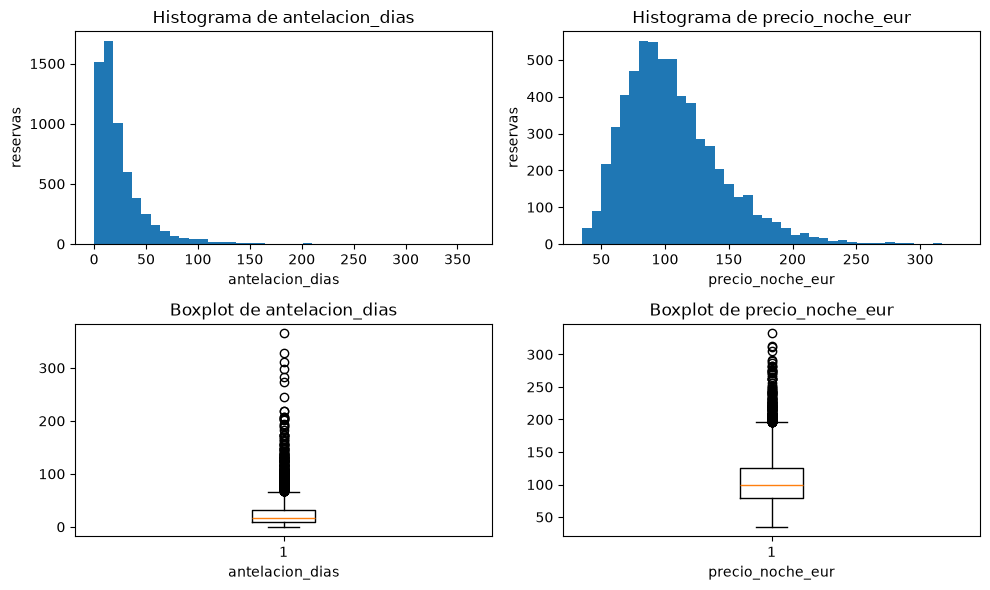

In [11]:
# Variables continuas: histograma (forma) y boxplot (mediana, cuartiles y puntos extremos)
fig, ax = plt.subplots(2, len(CONTINUAS), figsize=(10, 6))
for j, c in enumerate(CONTINUAS):
    ax[0, j].hist(X[c], bins=40)
    ax[0, j].set_title(f"Histograma de {c}")
    ax[0, j].set_xlabel(c)
    ax[0, j].set_ylabel("reservas")
    ax[1, j].boxplot(X[c])
    ax[1, j].set_title(f"Boxplot de {c}")
    ax[1, j].set_xlabel(c)
plt.tight_layout()
plt.show()

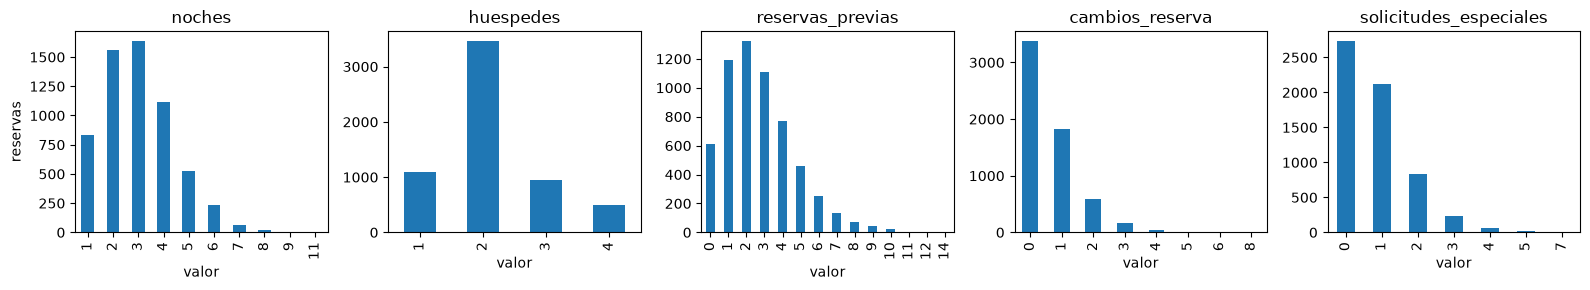

,% con valor 1
ausencias_previas,5.8
deposito_pagado,62.8
llegada_fin_semana,35.1


In [12]:
# Variables discretas (pocos valores enteros): gráfico de barras de frecuencias
fig, ax = plt.subplots(1, len(DISCRETAS), figsize=(16, 3))
for a, c in zip(ax, DISCRETAS):
    X[c].value_counts().sort_index().plot.bar(ax=a)
    a.set_title(c)
    a.set_xlabel("valor")
ax[0].set_ylabel("reservas")
plt.tight_layout()
plt.show()

# Variables binarias: porcentaje de reservas con valor 1
display((X[BINARIAS].mean() * 100).round(1).rename("% con valor 1").to_frame())

In [13]:
# Valores atípicos según la regla del boxplot: fuera de [Q1 - 1,5·IQR, Q3 + 1,5·IQR].
# Se aplica solo a las continuas: en variables con pocos valores esta regla marca como
# "atípicos" valores totalmente normales.
def n_atipicos_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

atipicos = pd.DataFrame({
    "n_atipicos": X[CONTINUAS].apply(n_atipicos_iqr),
    "% de reservas": (X[CONTINUAS].apply(n_atipicos_iqr) / len(X) * 100).round(1),
    "percentil 99": X[CONTINUAS].quantile(0.99).round(1),
    "máximo": X[CONTINUAS].max(),
})
display(atipicos)

,n_atipicos,% de reservas,percentil 99,máximo
antelacion_dias,361,6.0,130.0,365.00
precio_noche_eur,153,2.6,223.5,332.19


#### Variable objetivo: proporción de clases

Es el análisis univariante de no_presentado. De aquí salen la elección de la métrica, la estratificación y la necesidad de tratar el desequilibrio.

Negativos (0, se presenta):      5520  (92.0%)
Positivos (1, no se presenta):   480  (8.0%)
Ratio negativos : positivos = 11.5 : 1


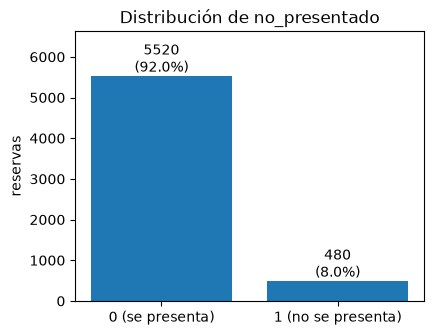

In [14]:
# Recuentos, porcentajes y ratio de desequilibrio (sobre el dataset completo, antes de partirlo)
conteo = y.value_counts().sort_index()
prop = y.value_counts(normalize=True).sort_index()
print(f"Negativos (0, se presenta):      {conteo[0]}  ({prop[0]:.1%})")
print(f"Positivos (1, no se presenta):   {conteo[1]}  ({prop[1]:.1%})")
print(f"Ratio negativos : positivos = {conteo[0] / conteo[1]:.1f} : 1")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(["0 (se presenta)", "1 (no se presenta)"], conteo.values)
for i, (n, p) in enumerate(zip(conteo, prop)):
    ax.text(i, n, f"{n}\n({p:.1%})", ha="center", va="bottom")
ax.set_ylim(0, conteo.max() * 1.2)
ax.set_ylabel("reservas")
ax.set_title("Distribución de no_presentado")
plt.show()

#### Partición entrenamiento / test y validación cruzada

Se aparta el 25 % para test (random_state=42, estratificado por la clase) antes de tomar ninguna decisión. La validación cruzada es un StratifiedKFold de 5 particiones sobre el entrenamiento, que se crea una sola vez y se reutiliza en todas las variantes. El test se usa al final, sin volver a ajustar con sus resultados.

In [15]:
# Partición entrenamiento / test (25 %), estratificada por la clase
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

print(f"Entrenamiento: {X_train.shape[0]} filas  |  Test: {X_test.shape[0]} filas")
print(f"Proporción de positivos (no_presentado = 1) en entrenamiento: {y_train.mean():.4f}")
print(f"Proporción de positivos (no_presentado = 1) en test:          {y_test.mean():.4f}")

Entrenamiento: 4500 filas  |  Test: 1500 filas
Proporción de positivos (no_presentado = 1) en entrenamiento: 0.0800
Proporción de positivos (no_presentado = 1) en test:          0.0800


In [16]:
# Validación cruzada estratificada sobre el entrenamiento.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [17]:
# Comprobación: tamaño y positivos de cada fold de validación.
filas = []
for i, (_, va) in enumerate(cv.split(X_train, y_train), start=1):
    filas.append({
        "fold": i,
        "reservas": len(va),
        "positivos": int(y_train.iloc[va].sum()),
        "% positivos": round(100 * y_train.iloc[va].mean(), 2),
    })
display(pd.DataFrame(filas).set_index("fold"))

,reservas,positivos,% positivos
fold,,,
1,900,72,8.0
2,900,72,8.0
3,900,72,8.0
4,900,72,8.0
5,900,72,8.0


#### Análisis bivariante (solo con entrenamiento)

Relación entre cada predictor y la clase. A partir de aquí se explora solo X_train / y_train: lo que se mire para tomar decisiones no debe incluir el test, que tiene que seguir siendo datos nuevos.

In [18]:
# Datos de entrenamiento con la clase, para explorar
d_train = X_train.assign(no_presentado=y_train)

# Variables binarias: % de no presentados según el valor de la variable
tasas = {c: d_train.groupby(c)["no_presentado"].mean().mul(100).round(1) for c in BINARIAS}
display(pd.DataFrame(tasas).T.add_prefix("% no presentados con valor "))

,% no presentados con valor 0,% no presentados con valor 1
ausencias_previas,7.4,18.3
deposito_pagado,12.9,5.1
llegada_fin_semana,8.0,8.0


In [19]:
# Variables continuas y discretas: media y mediana por clase
display(d_train.groupby("no_presentado")[CONTINUAS + DISCRETAS].agg(["mean", "median"]).T.round(2))

no_presentado                       0       1
antelacion_dias        mean     24.40   32.24
                       median   17.00   23.00
precio_noche_eur       mean    106.37  107.05
                       median   99.73   99.84
noches                 mean      3.00    3.11
                       median    3.00    3.00
huespedes              mean      2.14    2.15
                       median    2.00    2.00
reservas_previas       mean      2.78    1.64
                       median    2.00    1.00
cambios_reserva        mean      0.58    1.10
                       median    0.00    1.00
solicitudes_especiales mean      0.82    0.55
                       median    1.00    0.00

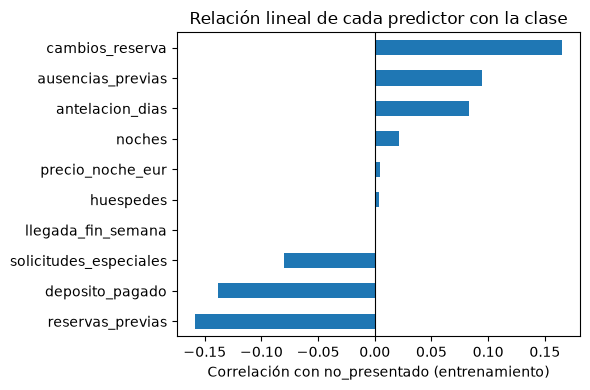

In [20]:
# Correlación de cada predictor con la clase (con una binaria es la correlación punto-biserial)
corr_y = d_train.corr()["no_presentado"].drop("no_presentado").sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
corr_y.plot.barh(ax=ax)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Correlación con no_presentado (entrenamiento)")
ax.set_title("Relación lineal de cada predictor con la clase")
plt.tight_layout()
plt.show()

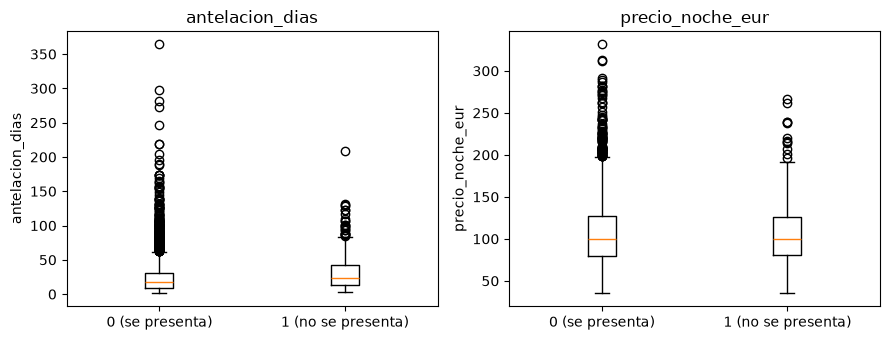

In [21]:
# Variables continuas por clase
fig, ax = plt.subplots(1, len(CONTINUAS), figsize=(9, 3.5))
for a, c in zip(ax, CONTINUAS):
    a.boxplot([d_train.loc[d_train.no_presentado == k, c] for k in (0, 1)])
    a.set_xticks([1, 2], ["0 (se presenta)", "1 (no se presenta)"])
    a.set_title(c)
    a.set_ylabel(c)
plt.tight_layout()
plt.show()

In [22]:
# Relaciones entre predictores: las 5 parejas con mayor correlación en valor absoluto
corr_X = X_train.corr().abs()
mascara = np.triu(np.ones(corr_X.shape, dtype=bool), k=1)
pares = corr_X.where(mascara).stack().sort_values(ascending=False)
display(pares.head(5).round(2).rename("|correlación|").to_frame())

|correlación|
reservas_previas deposito_pagado                  0.17
                 solicitudes_especiales           0.16
                 cambios_reserva                  0.15
antelacion_dias  reservas_previas                 0.13
cambios_reserva  deposito_pagado                  0.10

#### Métrica principal

La métrica principal es la F1 de la clase positiva (no_presentado = 1), fijada antes de comparar modelos. El hotel quiere llamar a los clientes con más riesgo de no presentarse sin contactar innecesariamente con demasiados, y los dos errores que importan son el falso negativo (habitación vacía sin aviso) y el falso positivo (llamada innecesaria). La F1 es la media armónica de recall y precision, que miden justo esos dos errores. La accuracy no sirve aquí: con un 92 % de clase 0, predecir siempre 0 da 0,92 sin detectar ni un solo no presentado.

Accuracy, precision, recall, especificidad y F1 se calculan con las etiquetas predichas y dependen del umbral (0,5 por defecto). ROC-AUC y PR-AUC usan probabilidades y no dependen de él. Todas se registran, pero solo la F1 decide la elección.

La F1 da el mismo peso a falsos positivos y falsos negativos, aunque el enunciado plantea que un falso negativo cuesta mucho más (70 € frente a 3 €), y el remuestreo cambia las probabilidades del modelo, así que la F1 al umbral 0,5 no es del todo comparable entre variantes. Esto se retoma al explorar los umbrales (apartado 6).

### Apartado 1 · Referencia y variantes básicas

Se compara la misma regresión logística con distintos tratamientos del desequilibrio, más una referencia que predice siempre 0. Todas las variantes usan el mismo cv (mismas 5 particiones estratificadas del entrenamiento) y encadenan escalado, remuestreo (si lo hay) y clasificador en un Pipeline, que es el de imblearn cuando hay remuestreo. Así el escalado y el remuestreo se ajustan solo con el entrenamiento de cada partición. La media y la desviación típica de cada métrica son en validación cruzada, no en test.

**Proporción de clases y accuracy de predecir siempre 0**

In [23]:
# Proporción de clases en el entrenamiento y accuracy de la referencia "siempre 0" (cálculo directo)
prop_train = y_train.value_counts(normalize=True).sort_index()
acc_siempre_0 = (y_train == 0).mean()

print("Proporción de clases en entrenamiento:")
print(prop_train.round(4).to_string())
print(f"\nAccuracy de predecir siempre 0: {acc_siempre_0:.4f}")
print("Coincide con la proporción de la clase 0, porque acierta exactamente las reservas que sí se presentan.")

Proporción de clases en entrenamiento:
no_presentado
0    0.92
1    0.08

Accuracy de predecir siempre 0: 0.9200
Coincide con la proporción de la clase 0, porque acierta exactamente las reservas que sí se presentan.


**Métricas y función de evaluación**

Se calculan en cada partición ocho métricas. F1, precision, recall, especificidad y accuracy salen de las etiquetas predichas; ROC-AUC, PR-AUC y AP, de las probabilidades. La PR-AUC se obtiene por integración trapezoidal de la curva precision–recall, y la AP (average precision) es una medida distinta que se registra aparte, identificada como tal. Con zero_division=0, una variante que nunca predice la clase positiva tiene precision 0 en lugar de un aviso.

In [24]:
# PR-AUC por integración trapezoidal (no es la average precision)
def pr_auc(y_true, y_score):
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    return auc(recall, precision)

# La F1 va primero porque es la métrica principal
scoring = {
    "f1":            make_scorer(f1_score, zero_division=0),
    "precision":     make_scorer(precision_score, zero_division=0),
    "recall":        make_scorer(recall_score),
    "especificidad": make_scorer(recall_score, pos_label=0),   # recall de la clase negativa
    "accuracy":      make_scorer(accuracy_score),
    "roc_auc":       make_scorer(roc_auc_score, response_method="predict_proba"),
    "pr_auc":        make_scorer(pr_auc, response_method="predict_proba"),
    "AP":            make_scorer(average_precision_score, response_method="predict_proba"),
}

resultados = {}   # nombre de la variante -> {métrica: (media, desviación típica)} en validación cruzada

def evaluar_cv(nombre, modelo):
    """Evalúa el modelo (o Pipeline) completo con el cv común y guarda media y desviación de cada métrica."""
    cv_res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring, error_score="raise")
    resultados[nombre] = {m: (cv_res[f"test_{m}"].mean(), cv_res[f"test_{m}"].std()) for m in scoring}

def tabla_resultados():
    """Tabla con "media ± desviación" de cada métrica para todas las variantes evaluadas."""
    filas = {n: {m: f"{mu:.3f} ± {sd:.3f}" for m, (mu, sd) in r.items()} for n, r in resultados.items()}
    return pd.DataFrame(filas).T

**Referencia y variantes básicas**

Cinco modelos de partida: la referencia, la regresión logística sin corrección y la misma regresión con submuestreo aleatorio (quita ejemplos de la clase mayoritaria), sobremuestreo aleatorio (duplica ejemplos de la minoritaria) y ponderación de clases (no cambia los datos, pesa más los errores de la minoritaria).

In [25]:
def regresion_logistica(**kwargs):
    return LogisticRegression(max_iter=1000, random_state=SEED, **kwargs)

modelos = {
    "Referencia (siempre 0)": DummyClassifier(strategy="most_frequent"),
    "LR sin corrección": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", regresion_logistica()),
    ]),
    "LR + submuestreo aleatorio": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomUnderSampler(random_state=SEED)),
        ("clf", regresion_logistica()),
    ]),
    "LR + sobremuestreo aleatorio": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(random_state=SEED)),
        ("clf", regresion_logistica()),
    ]),
    "LR + ponderación de clases": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", regresion_logistica(class_weight="balanced")),
    ]),
}

for nombre, modelo in modelos.items():
    evaluar_cv(nombre, modelo)

print("Resultados en VALIDACIÓN CRUZADA (5 particiones estratificadas del entrenamiento), media ± desviación:")
tabla_resultados()

Resultados en VALIDACIÓN CRUZADA (5 particiones estratificadas del entrenamiento), media ± desviación:


,f1,precision,recall,especificidad,accuracy,roc_auc,pr_auc,AP
Referencia (siempre 0),0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.920 ± 0.000,0.500 ± 0.000,0.540 ± 0.000,0.080 ± 0.000
LR sin corrección,0.058 ± 0.029,0.783 ± 0.194,0.031 ± 0.016,0.999 ± 0.001,0.922 ± 0.001,0.743 ± 0.015,0.242 ± 0.043,0.247 ± 0.042
LR + submuestreo aleatorio,0.250 ± 0.013,0.154 ± 0.009,0.669 ± 0.030,0.679 ± 0.020,0.678 ± 0.018,0.743 ± 0.015,0.226 ± 0.035,0.232 ± 0.035
LR + sobremuestreo aleatorio,0.254 ± 0.016,0.157 ± 0.011,0.672 ± 0.052,0.685 ± 0.021,0.684 ± 0.018,0.740 ± 0.018,0.239 ± 0.045,0.245 ± 0.044
LR + ponderación de clases,0.250 ± 0.017,0.154 ± 0.012,0.667 ± 0.043,0.680 ± 0.023,0.679 ± 0.022,0.741 ± 0.015,0.240 ± 0.043,0.245 ± 0.043


La referencia tiene un accuracy de 0,92 pero un F1 de 0, porque no detecta ningún no presentado. La regresión logística sin corrección apenas cambia esto: su accuracy es incluso algo mayor (0,922), pero el recall es de 0,03, casi siempre predice 0, y por eso el accuracy engaña. Las tres técnicas (submuestreo, sobremuestreo y ponderación de clases) suben el F1 hasta 0,25 y el recall hasta 0,67, a cambio de que la precisión baje a 0,15 y el accuracy a 0,68, porque ahora predicen muchos más positivos. Que el accuracy baje no significa que sean peores, es justo el efecto que buscamos con estas técnicas.

### Apartado 2 · Técnica de remuestreo: SMOTENC

**SMOTE y SMOTENC: qué hacen**

SMOTE (*Synthetic Minority Oversampling Technique*) es una técnica de sobremuestreo que, en lugar de copiar reservas de la clase minoritaria, crea reservas sintéticas interpolando entre una reserva positiva y uno de sus vecinos positivos más cercanos. El problema es que interpolar solo tiene sentido en variables continuas: entre dos reservas con deposito_pagado 0 y 1 podría salir 0,4. SMOTENC (*SMOTE for Nominal and Continuous*) resuelve eso: interpola las variables numéricas y, en las que se declaran categóricas, asigna el valor más frecuente entre los vecinos.

**Tratamiento de las variables en este ejercicio**

- Binarias (ausencias_previas, deposito_pagado, llegada_fin_semana): categóricas para SMOTENC, de modo que las reservas sintéticas solo toman 0 o 1.
- Discretas (noches, huespedes, reservas_previas, cambios_reserva, solicitudes_especiales) y continuas: numéricas, es decir, se interpolan. Las discretas son recuentos ordenados, y declararlas categóricas perdería ese orden; el coste es que pueden aparecer valores no enteros (por ejemplo 2,6 noches), que a una regresión logística, que ya las trata como números, no le suponen un problema.
- Escalado antes del remuestreo: SMOTENC elige vecinos con distancias, así que si no se escala, el precio (hasta 332) pesa mucho más que las noches. Se escalan solo las numéricas y las binarias pasan tal cual (0/1). Todo dentro del Pipeline, de modo que se ajusta solo con el entrenamiento de cada partición.

**Qué modifica SMOTENC (inspección con el entrenamiento completo)**

Esta celda es solo ilustrativa: se aplica el remuestreo una vez a todo X_train para ver qué genera. No se usa para evaluar. Se compara con SMOTE sin distinguir tipos de variable.

In [26]:
# Preprocesado del Pipeline de SMOTENC: escalar las numéricas y dejar pasar las binarias
NUMERICAS = CONTINUAS + DISCRETAS
def preprocesado_smotenc():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERICAS),
        ("bin", "passthrough", BINARIAS),
    ])

# Tras el ColumnTransformer las columnas quedan: primero las numéricas y después las binarias
idx_binarias = list(range(len(NUMERICAS), len(NUMERICAS) + len(BINARIAS)))

# --- SMOTENC (solo inspección) ---
pre = preprocesado_smotenc()
Xp = pre.fit_transform(X_train)
Xr, yr = SMOTENC(categorical_features=idx_binarias, random_state=SEED).fit_resample(Xp, y_train)
sintetico = Xr[len(Xp):]          # las filas nuevas se añaden al final

# --- SMOTE sin distinguir tipos (solo inspección): se escalan todas las columnas ---
esc = StandardScaler().fit(X_train)
Xr2, yr2 = SMOTE(random_state=SEED).fit_resample(esc.transform(X_train), y_train)
sintetico2 = esc.inverse_transform(Xr2[len(X_train):])
sintetico2 = pd.DataFrame(sintetico2, columns=X_train.columns)

print("Clases en el entrenamiento ANTES:  ", y_train.value_counts().sort_index().to_dict())
print("Clases en el entrenamiento DESPUÉS:", pd.Series(yr).value_counts().sort_index().to_dict())
n_pos = int((y_train == 1).sum())
print(f"Reservas sintéticas creadas: {len(sintetico)}  ->  unas {len(sintetico) / n_pos:.1f} por cada positivo real\n")

# Fracción de reservas sintéticas con un valor no válido en cada tipo de variable
bin_sntc = pd.DataFrame(sintetico[:, idx_binarias], columns=BINARIAS)
disc_sntc = pd.DataFrame(pre.named_transformers_["num"].inverse_transform(sintetico[:, :len(NUMERICAS)]),
                         columns=NUMERICAS)[DISCRETAS]
tabla = pd.DataFrame({
    "SMOTENC: binarias distintas de 0/1 (%)": 100 * (~bin_sntc.isin([0, 1])).mean(),
    "SMOTE: binarias distintas de 0/1 (%)":   100 * (~sintetico2[BINARIAS].round(6).isin([0, 1])).mean(),
}).round(1)
display(tabla)

# Proporción de reservas con valor 1 en cada binaria: reales frente a sintéticas
print("Proporción de 1 en cada binaria (reales y sintéticas):")
display(pd.DataFrame({
    "positivos reales":   X_train.loc[y_train == 1, BINARIAS].mean(),
    "negativos reales":   X_train.loc[y_train == 0, BINARIAS].mean(),
    "sintéticas SMOTENC": bin_sntc.mean(),
    "sintéticas SMOTE":   sintetico2[BINARIAS].mean(),
}).round(3))

print("Discretas con valor no entero en las reservas sintéticas (SMOTENC), en %:")
no_enteras = pd.DataFrame(~np.isclose(disc_sntc, disc_sntc.round()), columns=DISCRETAS).mean() * 100
display(no_enteras.round(1).to_frame("% no enteras").T)

Clases en el entrenamiento ANTES:   {0: 4140, 1: 360}
Clases en el entrenamiento DESPUÉS: {0: 4140, 1: 4140}
Reservas sintéticas creadas: 3780  ->  unas 10.5 por cada positivo real



,SMOTENC: binarias distintas de 0/1 (%),SMOTE: binarias distintas de 0/1 (%)
ausencias_previas,0.0,0.1
deposito_pagado,0.0,5.5
llegada_fin_semana,0.0,4.7


Proporción de 1 en cada binaria (reales y sintéticas):


,positivos reales,negativos reales,sintéticas SMOTENC,sintéticas SMOTE
ausencias_previas,0.133,0.052,0.033,0.132
deposito_pagado,0.403,0.649,0.339,0.398
llegada_fin_semana,0.353,0.353,0.256,0.338


Discretas con valor no entero en las reservas sintéticas (SMOTENC), en %:


,noches,huespedes,reservas_previas,cambios_reserva,solicitudes_especiales
% no enteras,53.9,23.9,63.2,29.2,24.7


**Evaluación en validación cruzada**

Se añaden al Pipeline dos variantes con la misma regresión logística, con el mismo cv y con las mismas métricas que en el apartado 1: SMOTENC (binarias como categóricas) y SMOTE sin distinguir tipos de variable, como comparación para ver si el tratamiento de las binarias importa en el resultado.

In [27]:
modelos["LR + SMOTENC"] = ImbPipeline([
    ("pre", preprocesado_smotenc()),
    ("sampler", SMOTENC(categorical_features=idx_binarias, random_state=SEED)),
    ("clf", regresion_logistica()),
])
modelos["LR + SMOTE (sin distinguir tipos)"] = ImbPipeline([
    ("scaler", StandardScaler()),
    ("sampler", SMOTE(random_state=SEED)),
    ("clf", regresion_logistica()),
])

for nombre in ["LR + SMOTENC", "LR + SMOTE (sin distinguir tipos)"]:
    evaluar_cv(nombre, modelos[nombre])

print("Resultados en VALIDACIÓN CRUZADA (5 particiones estratificadas del entrenamiento), media ± desviación:")
tabla_resultados()

Resultados en VALIDACIÓN CRUZADA (5 particiones estratificadas del entrenamiento), media ± desviación:


,f1,precision,recall,especificidad,accuracy,roc_auc,pr_auc,AP
Referencia (siempre 0),0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.920 ± 0.000,0.500 ± 0.000,0.540 ± 0.000,0.080 ± 0.000
LR sin corrección,0.058 ± 0.029,0.783 ± 0.194,0.031 ± 0.016,0.999 ± 0.001,0.922 ± 0.001,0.743 ± 0.015,0.242 ± 0.043,0.247 ± 0.042
LR + submuestreo aleatorio,0.250 ± 0.013,0.154 ± 0.009,0.669 ± 0.030,0.679 ± 0.020,0.678 ± 0.018,0.743 ± 0.015,0.226 ± 0.035,0.232 ± 0.035
LR + sobremuestreo aleatorio,0.254 ± 0.016,0.157 ± 0.011,0.672 ± 0.052,0.685 ± 0.021,0.684 ± 0.018,0.740 ± 0.018,0.239 ± 0.045,0.245 ± 0.044
LR + ponderación de clases,0.250 ± 0.017,0.154 ± 0.012,0.667 ± 0.043,0.680 ± 0.023,0.679 ± 0.022,0.741 ± 0.015,0.240 ± 0.043,0.245 ± 0.043
LR + SMOTENC,0.232 ± 0.007,0.144 ± 0.006,0.603 ± 0.035,0.687 ± 0.030,0.681 ± 0.025,0.712 ± 0.013,0.203 ± 0.019,0.209 ± 0.019
LR + SMOTE (sin distinguir tipos),0.252 ± 0.010,0.155 ± 0.007,0.669 ± 0.034,0.682 ± 0.019,0.681 ± 0.016,0.739 ± 0.013,0.234 ± 0.038,0.240 ± 0.038


SMOTENC añade reservas positivas sintéticas hasta igualar las clases (4.140 y 4.140), solo en el entrenamiento de cada partición; validación y test conservan el 8 %. En estos datos tiene dos inconvenientes. Salen unas 10,5 sintéticas por cada positivo real, generadas a partir de solo 360 reservas, y al asignar a las binarias el valor más frecuente entre vecinos las minoritarias se diluyen: ausencias_previas = 1 baja de 0,133 en los positivos reales a 0,033 en las sintéticas, y llegada_fin_semana de 0,353 a 0,256. Además, las clases se solapan, así que una sintética puede caer en zona de negativos.

SMOTE sin distinguir tipos de variable genera binarias no válidas (hasta 5,5 % en deposito_pagado), pero obtiene mejor resultado que SMOTENC (F1 0,252 frente a 0,232) y la diferencia supera las desviaciones típicas de ambos. Entre las variantes que corrigen el desequilibrio, SMOTENC es la peor en F1 y recall, y en estos datos generar reservas sintéticas no aporta nada sobre duplicar, quitar o ponderar.

**Tomek Links**

Se añade una técnica de otro tipo para contrastar con SMOTENC: en lugar de crear reservas sintéticas, elimina reservas de la clase mayoritaria. Un *Tomek link* es una pareja de reservas de clases distintas que son vecinas más cercanas entre sí; se quita la de la clase 0, para limpiar la frontera entre clases. No pretende igualar las clases, solo despejar la zona de solapamiento. Se mantiene el mismo Pipeline, el mismo cv y las mismas métricas.

In [28]:
# Inspección ilustrativa (no se usa para evaluar): qué elimina Tomek Links del entrenamiento completo escalado
esc_t = StandardScaler().fit(X_train)
Xt, yt = TomekLinks().fit_resample(esc_t.transform(X_train), y_train)

antes, despues = y_train.value_counts().sort_index(), pd.Series(yt).value_counts().sort_index()
print("Clases en el entrenamiento ANTES:  ", antes.to_dict())
print("Clases en el entrenamiento DESPUÉS:", despues.to_dict())
print(f"Reservas eliminadas: {len(X_train) - len(Xt)} (todas de la clase 0, que es la mayoritaria)")
print(f"Proporción de positivos: antes {antes[1] / antes.sum():.3%} -> después {despues[1] / despues.sum():.3%}")

Clases en el entrenamiento ANTES:   {0: 4140, 1: 360}
Clases en el entrenamiento DESPUÉS: {0: 3992, 1: 360}
Reservas eliminadas: 148 (todas de la clase 0, que es la mayoritaria)
Proporción de positivos: antes 8.000% -> después 8.272%


In [29]:
modelos["LR + Tomek Links"] = ImbPipeline([
    ("scaler", StandardScaler()),
    ("sampler", TomekLinks()),
    ("clf", regresion_logistica()),
])
evaluar_cv("LR + Tomek Links", modelos["LR + Tomek Links"])

print("Resultados en VALIDACIÓN CRUZADA (5 particiones estratificadas del entrenamiento), media ± desviación:")
tabla_resultados()

Resultados en VALIDACIÓN CRUZADA (5 particiones estratificadas del entrenamiento), media ± desviación:


,f1,precision,recall,especificidad,accuracy,roc_auc,pr_auc,AP
Referencia (siempre 0),0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.920 ± 0.000,0.500 ± 0.000,0.540 ± 0.000,0.080 ± 0.000
LR sin corrección,0.058 ± 0.029,0.783 ± 0.194,0.031 ± 0.016,0.999 ± 0.001,0.922 ± 0.001,0.743 ± 0.015,0.242 ± 0.043,0.247 ± 0.042
LR + submuestreo aleatorio,0.250 ± 0.013,0.154 ± 0.009,0.669 ± 0.030,0.679 ± 0.020,0.678 ± 0.018,0.743 ± 0.015,0.226 ± 0.035,0.232 ± 0.035
LR + sobremuestreo aleatorio,0.254 ± 0.016,0.157 ± 0.011,0.672 ± 0.052,0.685 ± 0.021,0.684 ± 0.018,0.740 ± 0.018,0.239 ± 0.045,0.245 ± 0.044
LR + ponderación de clases,0.250 ± 0.017,0.154 ± 0.012,0.667 ± 0.043,0.680 ± 0.023,0.679 ± 0.022,0.741 ± 0.015,0.240 ± 0.043,0.245 ± 0.043
LR + SMOTENC,0.232 ± 0.007,0.144 ± 0.006,0.603 ± 0.035,0.687 ± 0.030,0.681 ± 0.025,0.712 ± 0.013,0.203 ± 0.019,0.209 ± 0.019
LR + SMOTE (sin distinguir tipos),0.252 ± 0.010,0.155 ± 0.007,0.669 ± 0.034,0.682 ± 0.019,0.681 ± 0.016,0.739 ± 0.013,0.234 ± 0.038,0.240 ± 0.038
LR + Tomek Links,0.073 ± 0.033,0.695 ± 0.279,0.039 ± 0.018,0.998 ± 0.002,0.921 ± 0.002,0.743 ± 0.014,0.240 ± 0.045,0.246 ± 0.044


Tomek Links elimina reservas de la clase mayoritaria que son vecinas más cercanas de una positiva, para limpiar la frontera entre clases. Quita 148 reservas de la clase 0 (un 3,6 %) y no toca los positivos, así que la proporción de positivos pasa del 8,0 % al 8,3 %. El inconveniente en estos datos es que con un desbalance de 11,5 a 1 y clases muy solapadas apenas cambia el equilibrio, por lo que el modelo sigue entrenando casi con el mismo 8 % de positivos y se comporta como la regresión sin corrección: recall de 0,039 y F1 de 0,073 ± 0,033 frente a 0,058 ± 0,029 sin corrección, una diferencia menor que la desviación típica.

### Selección del modelo en validación cruzada

Todas las variantes se evalúan con el mismo cv. El criterio, fijado antes de comparar, es la F1 media de la clase positiva; la desviación típica se usa para saber si las diferencias son reales.

In [30]:
# Medias y desviaciones de la validación cruzada, como tablas numéricas
medias = pd.DataFrame({n: {m: mu for m, (mu, sd) in r.items()} for n, r in resultados.items()}).T
desvs  = pd.DataFrame({n: {m: sd for m, (mu, sd) in r.items()} for n, r in resultados.items()}).T

print("VALIDACIÓN CRUZADA: variantes ordenadas por la métrica principal (F1 de la clase positiva), solo medias")
display(medias.sort_values("f1", ascending=False).round(3))

# Criterio fijado de antemano: se elige la variante con mayor F1 media en validación cruzada
elegido = medias["f1"].idxmax()
f1_mu, f1_sd = medias.loc[elegido, "f1"], desvs.loc[elegido, "f1"]
print(f"\nModelo seleccionado: {elegido}  (F1 = {f1_mu:.3f} ± {f1_sd:.3f})")

# ¿Cuántas variantes quedan dentro de una desviación típica del seleccionado? (empate estadístico)
empatadas = [n for n in medias.index if n != elegido and medias.loc[n, "f1"] >= f1_mu - f1_sd]
print("Variantes cuyo F1 medio está a menos de una desviación típica del seleccionado:")
for n in empatadas:
    print(f"  - {n}: {medias.loc[n, 'f1']:.3f}")

VALIDACIÓN CRUZADA: variantes ordenadas por la métrica principal (F1 de la clase positiva), solo medias


,f1,precision,recall,especificidad,accuracy,roc_auc,pr_auc,AP
LR + sobremuestreo aleatorio,0.254,0.157,0.672,0.685,0.684,0.740,0.239,0.245
LR + SMOTE (sin distinguir tipos),0.252,0.155,0.669,0.682,0.681,0.739,0.234,0.240
LR + submuestreo aleatorio,0.250,0.154,0.669,0.679,0.678,0.743,0.226,0.232
LR + ponderación de clases,0.250,0.154,0.667,0.680,0.679,0.741,0.240,0.245
LR + SMOTENC,0.232,0.144,0.603,0.687,0.681,0.712,0.203,0.209
LR + Tomek Links,0.073,0.695,0.039,0.998,0.921,0.743,0.240,0.246
LR sin corrección,0.058,0.783,0.031,0.999,0.922,0.743,0.242,0.247
Referencia (siempre 0),0.000,0.000,0.000,1.000,0.920,0.500,0.540,0.080



Modelo seleccionado: LR + sobremuestreo aleatorio  (F1 = 0.254 ± 0.016)
Variantes cuyo F1 medio está a menos de una desviación típica del seleccionado:
  - LR + submuestreo aleatorio: 0.250
  - LR + ponderación de clases: 0.250
  - LR + SMOTE (sin distinguir tipos): 0.252


In [31]:
# Probabilidades de validación: cada reserva del entrenamiento recibe la probabilidad que le asigna el modelo
# cuando esa reserva estaba en la partición de validación (no se ha usado para entrenar ese modelo).
prob_cv = {}
for nombre, modelo in modelos.items():
    prob_cv[nombre] = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# Coste ilustrativo del enunciado: 70 € por falso negativo y 3 € por falso positivo
COSTE_FN, COSTE_FP = 70, 3

def coste_por_1000(y_true, y_pred):
    """Coste ilustrativo en euros por cada 1.000 reservas (permite comparar conjuntos de distinto tamaño)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    return (COSTE_FN * fn + COSTE_FP * fp) / len(y_true) * 1000

coste_val = pd.Series({n: coste_por_1000(y_train, prob_cv[n] >= 0.5) for n in modelos}, name="coste por 1.000 reservas (€)")
print("Coste ilustrativo en VALIDACIÓN, umbral 0,5 (predicciones de validación de las 5 particiones):")
display(coste_val.round(0).sort_values().to_frame())

Coste ilustrativo en VALIDACIÓN, umbral 0,5 (predicciones de validación de las 5 particiones):


,coste por 1.000 reservas (€)
LR + sobremuestreo aleatorio,2705.0
LR + SMOTE (sin distinguir tipos),2728.0
LR + submuestreo aleatorio,2737.0
LR + ponderación de clases,2749.0
LR + SMOTENC,3087.0
LR + Tomek Links,5388.0
LR sin corrección,5432.0
Referencia (siempre 0),5600.0


Las cuatro variantes con tratamiento básico del desequilibrio (sobremuestreo, SMOTE, submuestreo y ponderación) quedan en F1 ≈ 0,25 con diferencias menores que la desviación típica, así que están empatadas. Se elige el sobremuestreo aleatorio por tener la media más alta, siguiendo el criterio fijado de antemano. La regresión logística sin corrección tiene la accuracy más alta (0,92) pero la F1 más baja (0,06), y la métrica principal evita esa elección.

### Apartado 3 · Matriz de confusión en test

In [32]:
import os
os.makedirs("figuras", exist_ok=True)
os.makedirs("tablas", exist_ok=True)

ETIQUETAS_CLASE = ["0 · se presenta", "1 · no se presenta"]

def dibujar_matriz(ax, cm, titulo):
    """Matriz de confusión con filas = clase real y columnas = clase predicha."""
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1], ETIQUETAS_CLASE)
    ax.set_yticks([0, 1], ETIQUETAS_CLASE)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(titulo)
    nombres = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{nombres[i][j]}\n{cm[i, j]}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)

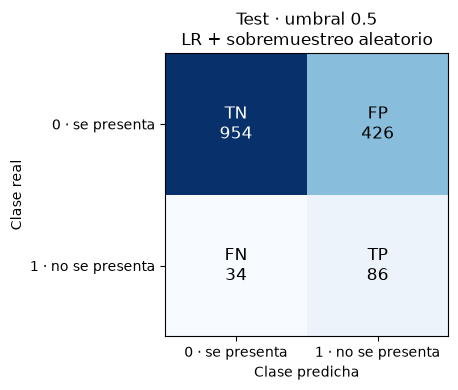

Qué representa cada casilla para el hotel (conjunto de TEST):
  TP = 86: reservas que no se presentan y el modelo marca para llamar (se puede recuperar la habitación).
  FN = 34: reservas que no se presentan y el modelo no marca (habitación vacía sin aviso, el error caro).
  FP = 426: reservas que sí se presentan y el modelo marca (llamada innecesaria, el error barato).
  TN = 954: reservas que se presentan y el modelo no marca (no se molesta al cliente).

Llamadas que haría el hotel: 512 de 1500 reservas; solo 86 de ellas serían a un no presentado.


In [33]:
# Se ajusta el modelo seleccionado con TODO el entrenamiento y se evalúa UNA vez en test, con el umbral por defecto
modelo_final = modelos[elegido]
modelo_final.fit(X_train, y_train)
prob_test = modelo_final.predict_proba(X_test)[:, 1]

UMBRAL_DEFECTO = 0.5
y_pred_test = (prob_test >= UMBRAL_DEFECTO).astype(int)

# Filas = clase real (0, 1); columnas = clase predicha (0, 1)  ->  [[TN, FP], [FN, TP]]
cm = confusion_matrix(y_test, y_pred_test, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(4.8, 4))
dibujar_matriz(ax, cm, f"Test · umbral {UMBRAL_DEFECTO}\n{elegido}")
plt.tight_layout()
fig.savefig("figuras/matriz_confusion_umbral_defecto.png", dpi=200, bbox_inches="tight")
plt.show()

print("Qué representa cada casilla para el hotel (conjunto de TEST):")
print(f"  TP = {tp}: reservas que no se presentan y el modelo marca para llamar (se puede recuperar la habitación).")
print(f"  FN = {fn}: reservas que no se presentan y el modelo no marca (habitación vacía sin aviso, el error caro).")
print(f"  FP = {fp}: reservas que sí se presentan y el modelo marca (llamada innecesaria, el error barato).")
print(f"  TN = {tn}: reservas que se presentan y el modelo no marca (no se molesta al cliente).")
print(f"\nLlamadas que haría el hotel: {tp + fp} de {len(y_test)} reservas; solo {tp} de ellas serían a un no presentado.")

Con filas reales y columnas predichas, los TP son los no presentados que el modelo marca (86): a esos se les llama y se puede reasignar la habitación. Los TN son los clientes que sí se presentan y a los que no se llama (954), que es lo ideal. Los FP son clientes que sí iban a venir y reciben una llamada innecesaria (426), un error barato pero molesto. Los FN son no presentados que el modelo no detecta (34), que acaban en una habitación vacía sin aviso y son el error caro. Con el umbral 0,5 se marcan 512 de las 1.500 reservas de test.

### Apartado 4 · Métricas y comprobación manual

In [34]:
# Métricas a mano a partir de la matriz de confusión
accuracy_m      = (tp + tn) / (tp + tn + fp + fn)
precision_m     = tp / (tp + fp)
recall_m        = tp / (tp + fn)
especificidad_m = tn / (tn + fp)
f1_m            = 2 * precision_m * recall_m / (precision_m + recall_m)
fpr_m           = fp / (fp + tn)

# Las mismas métricas con scikit-learn
metricas = pd.DataFrame({
    "a mano": [accuracy_m, precision_m, recall_m, especificidad_m, f1_m],
    "scikit-learn": [accuracy_score(y_test, y_pred_test),
                     precision_score(y_test, y_pred_test),
                     recall_score(y_test, y_pred_test),
                     recall_score(y_test, y_pred_test, pos_label=0),   # especificidad = recall de la clase 0
                     f1_score(y_test, y_pred_test)],
}, index=["accuracy", "precision", "recall (sensibilidad)", "especificidad", "F1"])
metricas["coinciden"] = np.isclose(metricas["a mano"], metricas["scikit-learn"])
print(f"Métricas en TEST, umbral {UMBRAL_DEFECTO}:")
display(metricas.round(4))
assert metricas["coinciden"].all(), "Alguna métrica a mano no coincide con scikit-learn"

# FPR = 1 - especificidad
print(f"FPR = FP / (FP + TN) = {fpr_m:.4f}   |   1 - especificidad = {1 - especificidad_m:.4f}")
assert np.isclose(fpr_m, 1 - especificidad_m)

Métricas en TEST, umbral 0.5:


,a mano,scikit-learn,coinciden
accuracy,0.6933,0.6933,True
precision,0.1680,0.1680,True
recall (sensibilidad),0.7167,0.7167,True
especificidad,0.6913,0.6913,True
F1,0.2722,0.2722,True


FPR = FP / (FP + TN) = 0.3087   |   1 - especificidad = 0.3087


Calculadas a mano con la matriz, precision = 86/512 = 0,168, recall = 86/120 = 0,717 y especificidad = 954/1.380 = 0,691, y coinciden con las de scikit-learn. La precisión y la especificidad miden cosas distintas: la precisión es el porcentaje de llamadas que acaban siendo a un no presentado (86 de 512), mientras que la especificidad es el porcentaje de clientes que sí se presentan a los que no se llama (954 de 1.380). Una especificidad de 0,69 parece aceptable, pero como hay 11,5 veces más presentados que no presentados, los 426 falsos positivos superan con mucho a los 86 verdaderos positivos, y por eso la precisión es tan baja. También se comprueba que FPR = 1 − especificidad = 0,309.

### Apartado 5 · Curvas ROC y precision–recall

In [35]:
def dibujar_curvas(y_true, y_prob, umbrales, titulo):
    """Curvas ROC y precision-recall (dos paneles) construidas con probabilidades, marcando umbrales."""
    y_true = np.asarray(y_true)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    prec, rec, _ = precision_recall_curve(y_true, y_prob)
    roc_auc_v = auc(fpr, tpr)
    pr_auc_v = auc(rec, prec)                          # integración trapezoidal
    ap_v = average_precision_score(y_true, y_prob)     # AP: medida distinta, se identifica aparte
    prevalencia = y_true.mean()

    fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
    ax[0].plot(fpr, tpr, label=f"Modelo (ROC-AUC = {roc_auc_v:.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", label="Azar (ROC-AUC = 0,5)")
    ax[1].plot(rec, prec, label=f"Modelo (PR-AUC = {pr_auc_v:.3f}; AP = {ap_v:.3f})")
    ax[1].axhline(prevalencia, color="k", ls="--", label=f"Azar (precision = prevalencia = {prevalencia:.2f})")

    for t, marcador in zip(umbrales, ["o", "s", "^"]):
        pred = (y_prob >= t).astype(int)
        tn_, fp_, fn_, tp_ = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        ax[0].scatter(fp_ / (fp_ + tn_), tp_ / (tp_ + fn_), marker=marcador, s=70, zorder=3, label=f"Umbral {t}")
        ax[1].scatter(tp_ / (tp_ + fn_), tp_ / (tp_ + fp_) if tp_ + fp_ else 0, marker=marcador, s=70, zorder=3,
                      label=f"Umbral {t}")

    ax[0].set(xlabel="Tasa de falsos positivos (FPR = 1 - especificidad)", ylabel="Tasa de verdaderos positivos (recall)",
              title="Curva ROC")
    ax[1].set(xlabel="Recall", ylabel="Precision", title="Curva precision-recall")
    for a in ax:
        a.grid(alpha=0.3)
        a.legend(loc="lower right" if a is ax[0] else "upper right", fontsize=8)
    fig.suptitle(titulo)
    plt.tight_layout()
    return fig, {"roc_auc": roc_auc_v, "pr_auc": pr_auc_v, "AP": ap_v, "prevalencia": prevalencia}

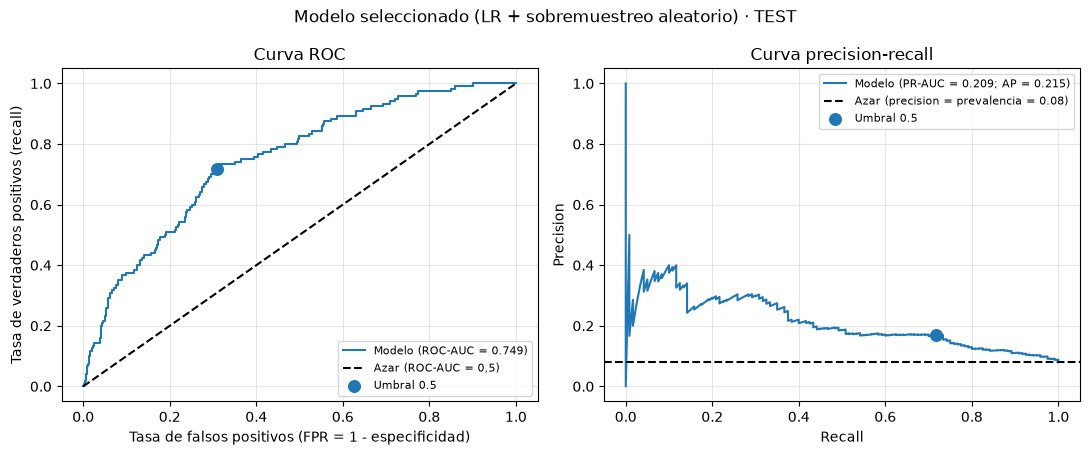

ROC-AUC = 0.749   PR-AUC (trapezoidal) = 0.209   AP = 0.215   prevalencia = 0.080


In [36]:
# Curvas del modelo seleccionado en TEST, construidas con las probabilidades (no con las etiquetas 0/1)
fig, auc_test = dibujar_curvas(y_test, prob_test, [UMBRAL_DEFECTO],
                               f"Modelo seleccionado ({elegido}) · TEST")
fig.savefig("figuras/curvas_roc_pr_umbral_defecto.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"ROC-AUC = {auc_test['roc_auc']:.3f}   PR-AUC (trapezoidal) = {auc_test['pr_auc']:.3f}   "
      f"AP = {auc_test['AP']:.3f}   prevalencia = {auc_test['prevalencia']:.3f}")

Las curvas se construyen con las probabilidades del modelo y no con las etiquetas 0/1: se ordenan las reservas de test por probabilidad y cada punto de la curva es un umbral, con (FPR, recall) en la ROC y (recall, precisión) en la PR. La ROC-AUC es 0,749, es decir, el modelo da más probabilidad a un no presentado que a uno que sí se presenta el 75 % de las veces (0,5 sería azar). La PR-AUC por integración trapezoidal es 0,209 y la average precision (AP) es 0,215. Son medidas distintas aunque aquí salgan parecidas, por eso la AP se identifica aparte. En la PR la línea de azar es la prevalencia (0,08) y no 0,5: el modelo la supera, pero la precisión cae rápido al subir el recall.

### Apartado 6 · Umbrales

**Exploración de umbrales (validación)**

Se usan las probabilidades de validación del modelo seleccionado (cada reserva puntuada por un modelo que no la vio) y los umbrales 0,3, 0,5 y 0,7. El umbral no cambia el modelo, solo decide a partir de qué probabilidad se llama. Se elige con el coste ilustrativo del enunciado (70 € por falso negativo, 3 € por falso positivo), calculado en validación; el test no interviene en la elección.

In [37]:
# Exploración de umbrales en VALIDACIÓN: probabilidades de validación del modelo seleccionado (solo entrenamiento)
UMBRALES = [0.3, 0.5, 0.7]

def metricas_umbral(y_true, y_prob, t):
    pred = (y_prob >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "umbral": t,
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "especificidad": tn_ / (tn_ + fp_),
        "F1": f1_score(y_true, pred, zero_division=0),
        "FP": fp_, "FN": fn_,
        "llamadas": tp_ + fp_,
        "coste por 1.000 reservas (€)": coste_por_1000(y_true, pred),
    }

tabla_umbrales = pd.DataFrame([metricas_umbral(y_train, prob_cv[elegido], t) for t in UMBRALES]).set_index("umbral")
print(f"VALIDACIÓN (probabilidades de validación del entrenamiento) · {elegido}")
display(tabla_umbrales.round(3))

VALIDACIÓN (probabilidades de validación del entrenamiento) · LR + sobremuestreo aleatorio


,precision,recall,especificidad,F1,FP,FN,llamadas,coste por 1.000 reservas (€)
umbral,,,,,,,,
0.3,0.109,0.914,0.349,0.195,2694,31,3023,2278.222
0.5,0.157,0.672,0.685,0.254,1304,118,1546,2704.889
0.7,0.241,0.331,0.910,0.279,374,241,493,3998.222


In [38]:
# Elección del umbral: el de menor coste ilustrativo en validación (la F1 pesa igual FP y FN; el hotel no)
UMBRAL = float(tabla_umbrales["coste por 1.000 reservas (€)"].idxmin())
print(f"Umbral elegido (queda fijado a partir de aquí): {UMBRAL}")
print(f"F1 en validación: {tabla_umbrales.loc[UMBRAL, 'F1']:.3f} (con 0,5: {tabla_umbrales.loc[0.5, 'F1']:.3f})")

Umbral elegido (queda fijado a partir de aquí): 0.3
F1 en validación: 0.195 (con 0,5: 0.254)


**Test con el umbral elegido**

Se compara, solo en test y sin reajustar, el umbral por defecto con el elegido en validación.

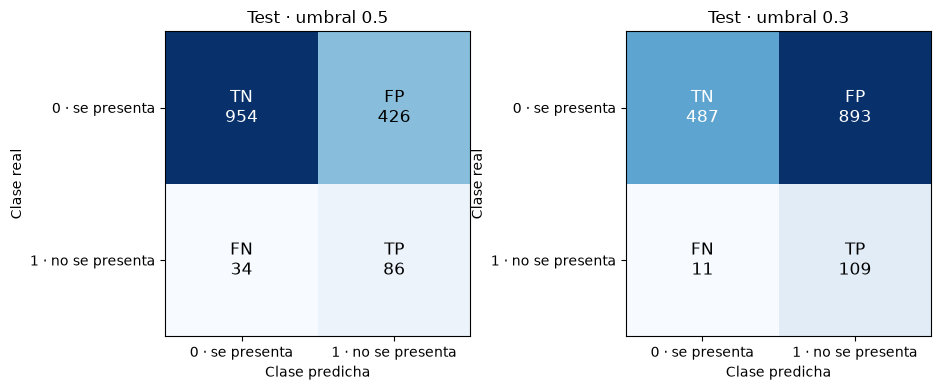

TEST (umbral fijado en validación):


,precision,recall,especificidad,F1,FP,FN,llamadas,coste por 1.000 reservas (€)
umbral,,,,,,,,
0.3,0.109,0.908,0.353,0.194,893,11,1002,2299.333
0.5,0.168,0.717,0.691,0.272,426,34,512,2438.667


In [39]:
# Evaluación en TEST (una sola vez, sin volver a ajustar): umbral por defecto frente al umbral elegido
y_pred_elegido = (prob_test >= UMBRAL).astype(int)
cm_elegido = confusion_matrix(y_test, y_pred_elegido, labels=[0, 1])

fig, ax = plt.subplots(1, 2, figsize=(9.5, 4))
dibujar_matriz(ax[0], cm, f"Test · umbral {UMBRAL_DEFECTO}")
dibujar_matriz(ax[1], cm_elegido, f"Test · umbral {UMBRAL}")
plt.tight_layout()
fig.savefig("figuras/matrices_umbral_defecto_vs_elegido.png", dpi=200, bbox_inches="tight")
plt.show()

filas_test = pd.DataFrame([metricas_umbral(y_test, prob_test, t) for t in sorted({UMBRAL_DEFECTO, UMBRAL})]).set_index("umbral")
print("TEST (umbral fijado en validación):")
display(filas_test.round(3))

Con los umbrales 0,3, 0,5 y 0,7 en validación, el 0,7 da el mejor F1 (0,279) pero el recall más bajo, y el 0,3 da el menor coste ilustrativo (70 € por FN y 3 € por FP). Elegimos 0,3 porque el F1 se usó para ordenar las técnicas con un umbral común, mientras que el umbral es el punto de operación y tiene que responder al objetivo del hotel, donde un FN pesa 23 veces más que un FP y el F1 los trata casi igual. La consecuencia es que el F1 baja a 0,194 en test (0,272 con 0,5), y lo asumimos.

Al bajar el umbral de 0,5 a 0,3 el modelo marca más reservas como positivas: los FN pasan de 34 a 11 y los FP suben de 426 a 893, así que el recall sube de 0,72 a 0,91 pero la precisión baja de 0,17 a 0,11 y la especificidad de 0,69 a 0,35.

Una ROC-AUC alta no garantiza una precisión alta en la clase minoritaria porque el FPR divide los falsos positivos entre todos los negativos, que son el 92 % de los datos. Un FPR de 0,31 parece moderado, pero son 426 llamadas innecesarias frente a solo 86 aciertos, y por eso la precisión es 0,17.

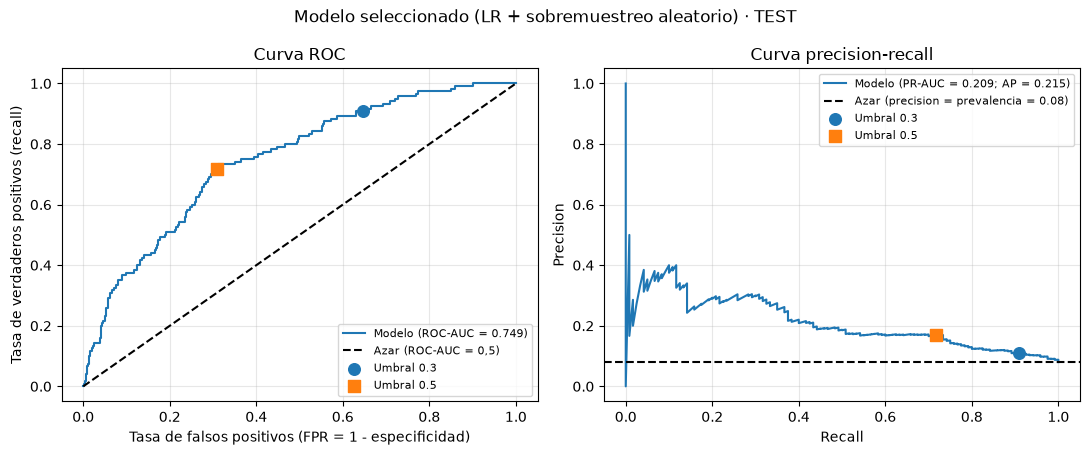

Con el umbral 0.3: 1002 llamadas, 109 a no presentados (9.2 llamadas por no presentado detectado).


In [40]:
# Figura final de curvas con los dos umbrales marcados (para el informe)
fig, _ = dibujar_curvas(y_test, prob_test, sorted({UMBRAL_DEFECTO, UMBRAL}),
                        f"Modelo seleccionado ({elegido}) · TEST")
fig.savefig("figuras/curvas_roc_pr_final.png", dpi=200, bbox_inches="tight")
plt.show()

# Cuántas llamadas por no presentado detectado (con el umbral elegido, en test)
tn_e, fp_e, fn_e, tp_e = cm_elegido.ravel()
print(f"Con el umbral {UMBRAL}: {tp_e + fp_e} llamadas, {tp_e} a no presentados ({(tp_e + fp_e) / tp_e:.1f} llamadas por no presentado detectado).")

### Tabla resumen de las variantes

In [41]:
# Tabla resumen de las variantes: resultados en VALIDACIÓN CRUZADA (media ± desviación) y coste en validación
cols_resumen = ["f1", "precision", "recall", "accuracy", "roc_auc", "pr_auc"]
resumen = pd.DataFrame({
    m: [f"{medias.loc[n, m]:.3f} ± {desvs.loc[n, m]:.3f}" for n in medias.index] for m in cols_resumen
}, index=medias.index)
resumen["coste por 1.000 reservas (€)"] = coste_val.round(0).astype(int)
resumen.columns = ["F1", "precision", "recall", "accuracy", "ROC-AUC", "PR-AUC (trapezoidal)", "coste por 1.000 reservas (€)"]
print("Resumen de variantes · VALIDACIÓN CRUZADA (umbral 0,5; el coste usa las predicciones de validación):")
display(resumen)
resumen.to_csv("tablas/ej1_resumen_variantes_cv.csv")

# Modelo seleccionado: validación cruzada frente a test
comparacion = pd.DataFrame({
    "Validación cruzada, umbral 0,5": {"F1": f"{medias.loc[elegido, 'f1']:.3f} ± {desvs.loc[elegido, 'f1']:.3f}",
                                        "precision": f"{medias.loc[elegido, 'precision']:.3f} ± {desvs.loc[elegido, 'precision']:.3f}",
                                        "recall": f"{medias.loc[elegido, 'recall']:.3f} ± {desvs.loc[elegido, 'recall']:.3f}",
                                        "accuracy": f"{medias.loc[elegido, 'accuracy']:.3f} ± {desvs.loc[elegido, 'accuracy']:.3f}"},
    f"Test, umbral {UMBRAL_DEFECTO}": {"F1": f"{filas_test.loc[UMBRAL_DEFECTO, 'F1']:.3f}",
                                      "precision": f"{filas_test.loc[UMBRAL_DEFECTO, 'precision']:.3f}",
                                      "recall": f"{filas_test.loc[UMBRAL_DEFECTO, 'recall']:.3f}",
                                      "accuracy": f"{accuracy_score(y_test, y_pred_test):.3f}"},
    f"Test, umbral {UMBRAL}": {"F1": f"{filas_test.loc[UMBRAL, 'F1']:.3f}",
                               "precision": f"{filas_test.loc[UMBRAL, 'precision']:.3f}",
                               "recall": f"{filas_test.loc[UMBRAL, 'recall']:.3f}",
                               "accuracy": f"{accuracy_score(y_test, y_pred_elegido):.3f}"},
})
print(f"Modelo seleccionado ({elegido}): validación cruzada frente a test")
display(comparacion)
comparacion.to_csv("tablas/ej1_cv_vs_test.csv")

# ¿Cambiaría la elección mirando solo la accuracy?
print(f"\nPor F1 en validación cruzada se elige:       {medias['f1'].idxmax()}")
print(f"Por accuracy en validación cruzada se elegiría: {medias['accuracy'].idxmax()}  (accuracy = {medias['accuracy'].max():.3f}, F1 = {medias.loc[medias['accuracy'].idxmax(), 'f1']:.3f})")

Resumen de variantes · VALIDACIÓN CRUZADA (umbral 0,5; el coste usa las predicciones de validación):


,F1,precision,recall,accuracy,ROC-AUC,PR-AUC (trapezoidal),coste por 1.000 reservas (€)
Referencia (siempre 0),0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.920 ± 0.000,0.500 ± 0.000,0.540 ± 0.000,5600
LR sin corrección,0.058 ± 0.029,0.783 ± 0.194,0.031 ± 0.016,0.922 ± 0.001,0.743 ± 0.015,0.242 ± 0.043,5432
LR + submuestreo aleatorio,0.250 ± 0.013,0.154 ± 0.009,0.669 ± 0.030,0.678 ± 0.018,0.743 ± 0.015,0.226 ± 0.035,2737
LR + sobremuestreo aleatorio,0.254 ± 0.016,0.157 ± 0.011,0.672 ± 0.052,0.684 ± 0.018,0.740 ± 0.018,0.239 ± 0.045,2705
LR + ponderación de clases,0.250 ± 0.017,0.154 ± 0.012,0.667 ± 0.043,0.679 ± 0.022,0.741 ± 0.015,0.240 ± 0.043,2749
LR + SMOTENC,0.232 ± 0.007,0.144 ± 0.006,0.603 ± 0.035,0.681 ± 0.025,0.712 ± 0.013,0.203 ± 0.019,3087
LR + SMOTE (sin distinguir tipos),0.252 ± 0.010,0.155 ± 0.007,0.669 ± 0.034,0.681 ± 0.016,0.739 ± 0.013,0.234 ± 0.038,2728
LR + Tomek Links,0.073 ± 0.033,0.695 ± 0.279,0.039 ± 0.018,0.921 ± 0.002,0.743 ± 0.014,0.240 ± 0.045,5388


Modelo seleccionado (LR + sobremuestreo aleatorio): validación cruzada frente a test


,"Validación cruzada, umbral 0,5","Test, umbral 0.5","Test, umbral 0.3"
F1,0.254 ± 0.016,0.272,0.194
precision,0.157 ± 0.011,0.168,0.109
recall,0.672 ± 0.052,0.717,0.908
accuracy,0.684 ± 0.018,0.693,0.397



Por F1 en validación cruzada se elige:       LR + sobremuestreo aleatorio
Por accuracy en validación cruzada se elegiría: LR sin corrección  (accuracy = 0.922, F1 = 0.058)


Los resultados de test (umbral 0,5) están en línea con los de validación cruzada: F1 de 0,272 frente a 0,254 ± 0,016, precisión de 0,168 frente a 0,157 y recall de 0,717 frente a 0,672. No vemos señal de sobreajuste a la validación, y que el test salga algo mejor entra dentro de la variabilidad esperada con solo 120 positivos.

Si miráramos solo el accuracy la elección cambiaría: ganaría la regresión sin corrección (0,922, con 0,920 para la referencia), que tiene un F1 de 0,058 y un recall de 0,031, es decir, un modelo que casi no detecta no presentados. Con el accuracy descartaríamos justo las variantes con remuestreo, que son las útiles para el hotel.

La curva PR es especialmente útil aquí porque la clase positiva es solo el 8 %. La ROC divide los falsos positivos entre todos los negativos y puede verse bien aunque haya muchas llamadas inútiles, mientras que la precisión de la PR compara los FP con los positivos detectados y muestra lo que cuesta cada no presentado detectado. Además su línea de azar es la prevalencia (0,08), no 0,5.

Recomendamos el sobremuestreo aleatorio con umbral 0,3 (empatado con submuestreo, ponderación y SMOTE, y elegido por la regla fijada de antemano). Con el coste ilustrativo calculado en validación, el umbral 0,5 cuesta 2.705 € por cada 1.000 reservas y el 0,3 cuesta 2.278 €, mientras que llamar a todos costaría 2.760 € y no llamar a nadie 5.600 €. Aceptamos llamar a muchos clientes que sí se presentan (casi el 65 % de ellos en test) para detectar el 91 % de los no presentados.

## 2. Ejercicio 2 · Qué dicen las reseñas

Los dos problemas usan características ya extraídas del texto (recuentos de expresiones, exclamaciones, etc.). Los archivos son independientes.

In [42]:
# Imports adicionales de los ejercicios 2A y 2B
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (classification_report, precision_recall_fscore_support,
                             multilabel_confusion_matrix, hamming_loss, ConfusionMatrixDisplay)

### 2A · Una valoración por reseña

Objetivo: predecir si una reseña es negativa, neutra o positiva (una sola clase por reseña). Se leen los datos, se comprueba su calidad, se exploran las frecuencias, se parte con estratificación por clase y se compara una referencia mayoritaria con una regresión logística multiclase con escalado.

In [43]:
dv = pd.read_csv("data/02_reseñas_valoracion.csv")
Xv = dv.drop(columns=["id_reseña", "valoracion"])
yv = dv["valoracion"]
print(f"Filas: {dv.shape[0]}  |  Columnas: {dv.shape[1]}  |  Predictores: {Xv.shape[1]}")
display(dv.head())

# Calidad básica: faltantes, duplicados (también sin contar el id), tipos y rangos
print("\nValores faltantes:", int(dv.isna().sum().sum()))
print("Filas duplicadas sin contar el id:", dv.drop(columns="id_reseña").duplicated().sum())
print("IDs duplicados:", dv["id_reseña"].duplicated().sum())
display(Xv.agg(["min", "max", "mean", "std"]).T.round(2))
assert (Xv >= 0).all().all(), "Hay valores negativos"
assert Xv["porcentaje_mayusculas"].between(0, 100).all(), "Porcentaje fuera de 0-100"
assert (Xv["n_palabras"] >= 1).all()

Filas: 3200  |  Columnas: 11  |  Predictores: 9


,id_reseña,n_palabras,n_expresiones_positivas,n_expresiones_negativas,n_intensificadores,n_exclamaciones,n_terminos_limpieza,n_terminos_personal,n_terminos_ubicacion,porcentaje_mayusculas,valoracion
0,V00000,78,2,0,0,1,0,2,3,3.6,positiva
1,V00001,128,2,0,0,2,1,1,2,9.5,neutra
2,V00002,102,8,1,0,1,0,1,3,3.0,positiva
3,V00003,37,0,1,2,0,2,1,1,7.8,neutra
4,V00004,133,9,0,2,1,2,4,0,10.1,positiva



Valores faltantes: 0
Filas duplicadas sin contar el id: 0
IDs duplicados: 0


,min,max,mean,std
n_palabras,10.0,200.0,105.99,54.50
n_expresiones_positivas,0.0,29.0,3.81,3.55
n_expresiones_negativas,0.0,25.0,2.57,2.74
n_intensificadores,0.0,9.0,1.09,1.10
n_exclamaciones,0.0,7.0,0.88,0.97
n_terminos_limpieza,0.0,8.0,1.48,1.23
n_terminos_personal,0.0,8.0,1.31,1.16
n_terminos_ubicacion,0.0,6.0,1.22,1.10
porcentaje_mayusculas,0.0,46.8,7.36,6.31


**Frecuencias de la variable objetivo**

,reseñas,proporción
valoracion,,
negativa,480,0.15
neutra,960,0.30
positiva,1760,0.55


Ratio clase mayoritaria : minoritaria = 3.67 : 1


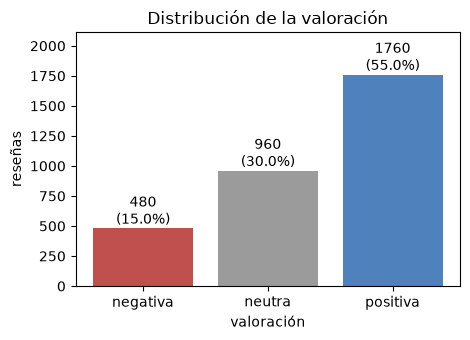

In [44]:
# Frecuencias de la variable objetivo (dataset completo, antes de partir)
ORDEN_V = ["negativa", "neutra", "positiva"]
frec_v = pd.DataFrame({"reseñas": yv.value_counts().reindex(ORDEN_V),
                       "proporción": yv.value_counts(normalize=True).reindex(ORDEN_V).round(3)})
display(frec_v)
print(f"Ratio clase mayoritaria : minoritaria = {frec_v['reseñas'].max() / frec_v['reseñas'].min():.2f} : 1")

fig, ax = plt.subplots(figsize=(4.8, 3.5))
ax.bar(ORDEN_V, frec_v["reseñas"], color=["#c0504d", "#9b9b9b", "#4f81bd"])
for i, (n, p) in enumerate(zip(frec_v["reseñas"], frec_v["proporción"])):
    ax.text(i, n, f"{n}\n({p:.1%})", ha="center", va="bottom")
ax.set_ylim(0, frec_v["reseñas"].max() * 1.2)
ax.set_ylabel("reseñas"); ax.set_xlabel("valoración"); ax.set_title("Distribución de la valoración")
plt.tight_layout()
fig.savefig("figuras/valoracion_distribucion_clases.png", dpi=200, bbox_inches="tight")
plt.show()

**Partición y validación cruzada**

25 % para test (random_state=42, estratificado por la clase) y StratifiedKFold de 5 particiones sobre el entrenamiento. Las medias por clase son exploración con solo el entrenamiento.

In [45]:
# Partición 75/25 estratificada por la clase y validación cruzada estratificada (solo sobre entrenamiento)
Xv_train, Xv_test, yv_train, yv_test = train_test_split(Xv, yv, test_size=0.25, random_state=SEED, stratify=yv)
cv_v = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Entrenamiento: {len(Xv_train)}  |  Test: {len(Xv_test)}")
display(pd.DataFrame({"entrenamiento": yv_train.value_counts(normalize=True).reindex(ORDEN_V),
                      "test": yv_test.value_counts(normalize=True).reindex(ORDEN_V)}).round(3))

# Exploración bivariante solo con entrenamiento: media de cada predictor por clase
display(Xv_train.groupby(yv_train).mean().reindex(ORDEN_V).T.round(2))

Entrenamiento: 2400  |  Test: 800


,entrenamiento,test
valoracion,,
negativa,0.15,0.15
neutra,0.30,0.30
positiva,0.55,0.55


valoracion,negativa,neutra,positiva
n_palabras,108.50,101.72,106.24
n_expresiones_positivas,1.75,2.55,5.00
n_expresiones_negativas,5.64,2.36,1.79
n_intensificadores,1.06,0.99,1.11
n_exclamaciones,0.97,0.81,0.88
n_terminos_limpieza,1.41,1.44,1.51
n_terminos_personal,1.30,1.28,1.31
n_terminos_ubicacion,1.21,1.27,1.20
porcentaje_mayusculas,7.81,6.91,7.50


Métrica principal (elegida antes de comparar): F1 macro.

Las clases están desbalanceadas (55 / 30 / 15 %) y la clase negativa, la menos frecuente, es probablemente la que más interesa al hotel. La F1 macro promedia la F1 de las tres clases con el mismo peso, así que un modelo que ignore la clase minoritaria sale penalizado. La accuracy no lo hace: la referencia mayoritaria alcanza 0,55 sin acertar ninguna negativa ni neutra. Se registran además precision y recall macro y accuracy como secundarias. Todas estas métricas usan etiquetas predichas, no probabilidades.

In [46]:
# Referencia mayoritaria y regresión logística multiclase con escalado, evaluadas en VALIDACIÓN CRUZADA
modelos_v = {
    "Referencia (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística multiclase": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]),
}
scoring_v = {"f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
             "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
             "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
             "accuracy": make_scorer(accuracy_score)}

filas = {}
for nombre, modelo in modelos_v.items():
    r = cross_validate(modelo, Xv_train, yv_train, cv=cv_v, scoring=scoring_v, error_score="raise")
    filas[nombre] = {m: f"{r[f'test_{m}'].mean():.3f} ± {r[f'test_{m}'].std():.3f}" for m in scoring_v}
print("VALIDACIÓN CRUZADA (5 particiones estratificadas del entrenamiento), media ± desviación; métrica principal: F1 macro")
display(pd.DataFrame(filas).T)

VALIDACIÓN CRUZADA (5 particiones estratificadas del entrenamiento), media ± desviación; métrica principal: F1 macro


,f1_macro,precision_macro,recall_macro,accuracy
Referencia (clase mayoritaria),0.237 ± 0.000,0.183 ± 0.000,0.333 ± 0.000,0.550 ± 0.000
Regresión logística multiclase,0.547 ± 0.011,0.590 ± 0.023,0.533 ± 0.010,0.628 ± 0.019


En validación cruzada la regresión logística obtiene un F1 macro de 0,547 ± 0,011 frente a 0,237 de la referencia, una diferencia mucho mayor que la desviación típica. El accuracy sube menos (de 0,550 a 0,628) porque la referencia acierta toda la clase mayoritaria. Como no se compara entre varios modelos candidatos no hay selección que hacer: el modelo se ajusta con todo el entrenamiento y se evalúa una sola vez en test.

In [47]:
# Ajuste final con todo el entrenamiento y predicción en TEST (una sola vez)
modelo_v = modelos_v["Regresión logística multiclase"].fit(Xv_train, yv_train)
base_v = modelos_v["Referencia (clase mayoritaria)"].fit(Xv_train, yv_train)
pred_v = modelo_v.predict(Xv_test)
print("Clases del modelo (orden de columnas):", list(modelo_v.classes_))
print(f"TEST · F1 macro: modelo = {f1_score(yv_test, pred_v, average='macro'):.3f} | "
      f"referencia = {f1_score(yv_test, base_v.predict(Xv_test), average='macro', zero_division=0):.3f}")

Clases del modelo (orden de columnas): ['negativa', 'neutra', 'positiva']
TEST · F1 macro: modelo = 0.550 | referencia = 0.237


### Apartado 7 · Matriz de confusión y clase negativa

Todos los resultados de 7, 8 y 9 son de test, con las etiquetas predichas (la clase de mayor probabilidad).

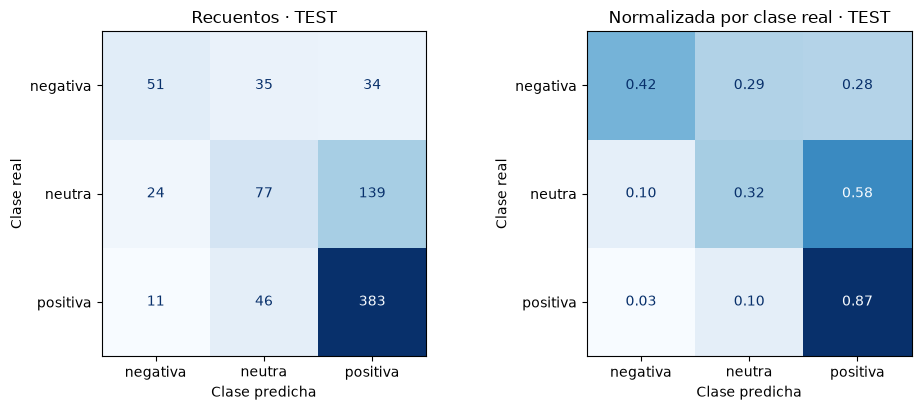

Clase negativa (resto = neutra + positiva):  TP = 51   FP = 35   FN = 69
A mano: precision = 51/(51+35) = 0.5930   recall = 51/(51+69) = 0.4250
Informe del modelo para la clase negativa: precision = 0.5930, recall = 0.4250


In [48]:
# Matriz de confusión: filas = clase real, columnas = clase predicha
cm_v = confusion_matrix(yv_test, pred_v, labels=ORDEN_V)
cm_v_norm = confusion_matrix(yv_test, pred_v, labels=ORDEN_V, normalize="true")   # cada fila suma 1

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, m, fmt, tit in [(ax[0], cm_v, "d", "Recuentos"), (ax[1], cm_v_norm, ".2f", "Normalizada por clase real")]:
    ConfusionMatrixDisplay(m, display_labels=ORDEN_V).plot(ax=a, cmap="Blues", values_format=fmt, colorbar=False)
    a.set_title(f"{tit} · TEST"); a.set_xlabel("Clase predicha"); a.set_ylabel("Clase real")
plt.tight_layout()
fig.savefig("figuras/valoracion_matrices_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

# Clase negativa frente al resto
i = ORDEN_V.index("negativa")
TP = cm_v[i, i]                    # negativas bien clasificadas
FN = cm_v[i, :].sum() - TP         # negativas reales clasificadas como neutra o positiva
FP = cm_v[:, i].sum() - TP         # neutras o positivas clasificadas como negativa
print(f"Clase negativa (resto = neutra + positiva):  TP = {TP}   FP = {FP}   FN = {FN}")
prec_neg, rec_neg = TP / (TP + FP), TP / (TP + FN)
print(f"A mano: precision = {TP}/({TP}+{FP}) = {prec_neg:.4f}   recall = {TP}/({TP}+{FN}) = {rec_neg:.4f}")

informe = pd.DataFrame(classification_report(yv_test, pred_v, labels=ORDEN_V, output_dict=True)).T
print("Informe del modelo para la clase negativa:",
      f"precision = {informe.loc['negativa', 'precision']:.4f}, recall = {informe.loc['negativa', 'recall']:.4f}")
assert np.isclose(prec_neg, informe.loc["negativa", "precision"]) and np.isclose(rec_neg, informe.loc["negativa", "recall"])

Para la clase negativa frente al resto, TP = 51 son negativas bien detectadas, FP = 35 son neutras o positivas que el modelo marca como negativas y FN = 69 son negativas que clasifica como neutras o positivas. La precision es 51/86 = 0,593 y el recall 51/120 = 0,425, iguales a los del informe del modelo.

La matriz normalizada por clase real (cada fila suma 1) permite comparar clases de distinto tamaño. Vemos que la positiva se reconoce bien (0,87), la negativa a medias (0,43) y la neutra peor (0,32), que se confunde con la positiva en el 58 % de los casos. Las 69 negativas perdidas se reparten casi a partes iguales entre neutra (35) y positiva (34).

### Apartado 8 · Métricas por clase y promedios

In [49]:
# Precision, recall y F1 por clase y promedios (TEST, etiquetas predichas)
print(classification_report(yv_test, pred_v, labels=ORDEN_V, digits=3))

p, r, f, soporte = precision_recall_fscore_support(yv_test, pred_v, labels=ORDEN_V)
resumen_v = pd.DataFrame({"precision": p, "recall": r, "F1": f, "soporte": soporte}, index=ORDEN_V)
promedios = {}
for prom in ["macro", "micro", "weighted"]:
    pp, rr, ff, _ = precision_recall_fscore_support(yv_test, pred_v, labels=ORDEN_V, average=prom)
    promedios[prom] = {"precision": pp, "recall": rr, "F1": ff}
promedios["accuracy"] = {"precision": np.nan, "recall": np.nan, "F1": accuracy_score(yv_test, pred_v)}
tabla_prom_v = pd.concat([resumen_v.drop(columns="soporte"),
                          pd.DataFrame(promedios).T.add_prefix("")]).round(3)
tabla_prom_v.index = list(ORDEN_V) + ["macro", "micro", "weighted", "accuracy"]
display(tabla_prom_v)
tabla_prom_v.to_csv("tablas/ej2a_metricas_promedios.csv")

# Reconstrucción manual de macro y weighted
w = soporte / soporte.sum()
print("Pesos macro:    ", {c: round(1/3, 3) for c in ORDEN_V})
print("Pesos weighted: ", {c: round(float(x), 3) for c, x in zip(ORDEN_V, w)})
f1_macro_m = f.mean()
f1_weighted_m = (f * soporte).sum() / soporte.sum()
print(f"F1 macro a mano    = ({' + '.join(f'{x:.3f}' for x in f)}) / 3 = {f1_macro_m:.4f}")
print(f"F1 weighted a mano = suma(F1_c · soporte_c) / {soporte.sum()} = {f1_weighted_m:.4f}")
assert np.isclose(f1_macro_m, promedios["macro"]["F1"]) and np.isclose(f1_weighted_m, promedios["weighted"]["F1"])

              precision    recall  f1-score   support

    negativa      0.593     0.425     0.495       120
      neutra      0.487     0.321     0.387       240
    positiva      0.689     0.870     0.769       440

    accuracy                          0.639       800
   macro avg      0.590     0.539     0.550       800
weighted avg      0.614     0.639     0.613       800



,precision,recall,F1
negativa,0.593,0.425,0.495
neutra,0.487,0.321,0.387
positiva,0.689,0.870,0.769
macro,0.590,0.539,0.550
micro,0.639,0.639,0.639
weighted,0.614,0.639,0.613
accuracy,NaN,NaN,0.639


Pesos macro:     {'negativa': 0.333, 'neutra': 0.333, 'positiva': 0.333}
Pesos weighted:  {'negativa': 0.15, 'neutra': 0.3, 'positiva': 0.55}
F1 macro a mano    = (0.495 + 0.387 + 0.769) / 3 = 0.5504
F1 weighted a mano = suma(F1_c · soporte_c) / 800 = 0.6133


En macro cada clase pesa lo mismo (1/3), en weighted pesa su proporción de reseñas reales (0,15, 0,30 y 0,55) y en micro cada reseña cuenta igual, así que domina la clase más grande. Reconstruyendo a mano, F1 macro = (0,495 + 0,387 + 0,769) / 3 = 0,550 y F1 weighted = 0,613, que coinciden con scikit-learn.

Los resultados globales (accuracy y F1 micro de 0,639, F1 weighted de 0,613) salen más altos que el macro porque la clase positiva, que es la mayoritaria y la mejor resuelta, pesa más. Con un único número se esconde que la neutra casi no se detecta (recall 0,32) y que la negativa se pierde en más de la mitad de los casos.

### Apartado 9 · Micro frente a accuracy y qué presentar

In [50]:
# En multiclase con una sola clase real y una predicha por reseña, micro = accuracy
comp = pd.Series({
    "precision micro": promedios["micro"]["precision"], "recall micro": promedios["micro"]["recall"],
    "F1 micro": promedios["micro"]["F1"], "accuracy": accuracy_score(yv_test, pred_v)})
display(comp.round(4).to_frame("TEST"))
assert np.allclose(comp.values, comp.values[0]), "Las medidas micro y accuracy no coinciden"
print("Coinciden. Aciertos totales / reseñas =", int(np.trace(cm_v)), "/", cm_v.sum(), "=", round(np.trace(cm_v) / cm_v.sum(), 4))

# Errores que oculta la medida global: recall de cada clase frente a la accuracy
print("\nRecall por clase (diagonal de la matriz normalizada):")
display(pd.Series(np.diag(cm_v_norm), index=ORDEN_V).round(3).to_frame("recall"))

# A dónde van las reseñas negativas mal clasificadas
print("Reseñas negativas reales (test) y clase predicha:")
display(pd.Series(cm_v[i, :], index=ORDEN_V).to_frame("reseñas"))

,TEST
precision micro,0.6388
recall micro,0.6388
F1 micro,0.6388
accuracy,0.6388


Coinciden. Aciertos totales / reseñas = 511 / 800 = 0.6388

Recall por clase (diagonal de la matriz normalizada):


,recall
negativa,0.425
neutra,0.321
positiva,0.870


Reseñas negativas reales (test) y clase predicha:


,reseñas
negativa,51
neutra,35
positiva,34


Precision micro, recall micro, F1 micro y accuracy valen lo mismo (0,639). Con una sola clase real y una predicha por reseña, cada error es a la vez un falso positivo para la clase predicha y un falso negativo para la real, así que las sumas de FP y de FN son iguales (reseñas menos aciertos) y precision micro = recall micro = aciertos / reseñas = accuracy.

Si lo prioritario es detectar reseñas negativas presentaríamos el recall de la clase negativa (0,425) junto con su precision (0,593) y su F1 (0,495), acompañados de la matriz normalizada por clase real. No presentaríamos el accuracy ni el F1 weighted, porque la negativa pesa solo el 15 % y quedan dominados por la positiva.

### 2B · Varios motivos de queja por reseña

Objetivo: predecir, para cada reseña, cuáles de las cuatro quejas contiene (limpieza, ruido, atención, instalaciones). Una reseña puede tener varias o ninguna, así que cada etiqueta es un problema binario.

In [51]:
dq = pd.read_csv("data/03_reseñas_quejas.csv")
ETIQUETAS = ["queja_limpieza", "queja_ruido", "queja_atencion", "queja_instalaciones"]
Xq = dq.drop(columns=["id_reseña"] + ETIQUETAS)
Yq = dq[ETIQUETAS]
print(f"Filas: {dq.shape[0]}  |  Predictores: {Xq.shape[1]}  |  Etiquetas: {Yq.shape[1]}")
display(dq.head())

print("\nValores faltantes:", int(dq.isna().sum().sum()))
print("Filas duplicadas sin contar el id:", dq.drop(columns="id_reseña").duplicated().sum())
display(Xq.agg(["min", "max", "mean", "std"]).T.round(2))
assert (Xq >= 0).all().all() and Xq["porcentaje_mayusculas"].between(0, 100).all()
for c in ETIQUETAS:
    assert set(dq[c].unique()) <= {0, 1}, f"{c} no es 0/1"

Filas: 2800  |  Predictores: 8  |  Etiquetas: 4


,id_reseña,n_palabras,n_expresiones_limpieza,n_expresiones_ruido,n_expresiones_atencion,n_expresiones_instalaciones,n_expresiones_negativas,n_exclamaciones,porcentaje_mayusculas,queja_limpieza,queja_ruido,queja_atencion,queja_instalaciones
0,Q00000,99,3,4,1,1,2,2,1.3,1,0,0,0
1,Q00001,158,0,0,0,1,1,3,2.1,0,0,0,0
2,Q00002,126,1,0,3,4,0,0,21.8,0,0,1,0
3,Q00003,63,3,0,0,2,4,1,2.1,1,0,1,0
4,Q00004,149,3,0,2,1,4,0,10.8,1,0,0,0



Valores faltantes: 0
Filas duplicadas sin contar el id: 0


,min,max,mean,std
n_palabras,10.0,200.0,105.04,54.96
n_expresiones_limpieza,0.0,46.0,1.66,2.26
n_expresiones_ruido,0.0,43.0,1.67,2.49
n_expresiones_atencion,0.0,29.0,1.65,2.21
n_expresiones_instalaciones,0.0,27.0,1.66,2.38
n_expresiones_negativas,0.0,9.0,1.55,1.34
n_exclamaciones,0.0,8.0,1.23,1.13
porcentaje_mayusculas,0.0,37.2,7.46,6.18


**Frecuencia de las etiquetas, quejas por reseña y reseñas sin quejas**

,reseñas con la queja,frecuencia
queja_limpieza,840,0.300
queja_ruido,769,0.275
queja_atencion,421,0.150
queja_instalaciones,289,0.103


Número medio de quejas por reseña: 0.828
Proporción de reseñas sin ninguna queja: 0.409
Distribución del número de quejas por reseña:


,reseñas
0,1144
1,1094
2,468
3,87
4,7


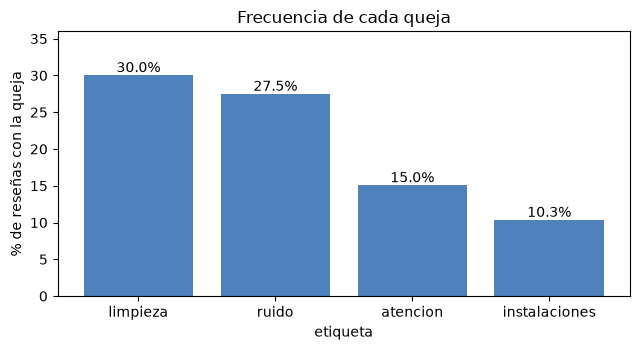

In [52]:
# Frecuencia de cada etiqueta, número medio de etiquetas por reseña y proporción sin quejas (dataset completo)
frec_q = pd.DataFrame({"reseñas con la queja": Yq.sum(), "frecuencia": Yq.mean().round(3)})
display(frec_q)
n_por_resena = Yq.sum(axis=1)
sin_quejas = (n_por_resena == 0).mean()
print(f"Número medio de quejas por reseña: {n_por_resena.mean():.3f}")
print(f"Proporción de reseñas sin ninguna queja: {sin_quejas:.3f}")
print("Distribución del número de quejas por reseña:")
display(n_por_resena.value_counts().sort_index().rename("reseñas").to_frame())

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar([e.replace("queja_", "") for e in ETIQUETAS], Yq.mean() * 100, color="#4f81bd")
for k, v in enumerate(Yq.mean() * 100):
    ax.text(k, v, f"{v:.1f}%", ha="center", va="bottom")
ax.set_ylabel("% de reseñas con la queja"); ax.set_xlabel("etiqueta"); ax.set_title("Frecuencia de cada queja")
ax.set_ylim(0, Yq.mean().max() * 100 * 1.2)
plt.tight_layout()
fig.savefig("figuras/quejas_frecuencia_etiquetas.png", dpi=200, bbox_inches="tight")
plt.show()

Las etiquetas están desbalanceadas: limpieza (30,0 %) y ruido (27,5 %) son frecuentes, mientras que atención (15,0 %) e instalaciones (10,3 %) son raras. De media hay 0,83 quejas por reseña y el 40,9 % no tiene ninguna, así que predecir ninguna queja ya acierta muchas decisiones sin aportar nada.

**Partición**

Partición aleatoria simple, 25 % para test con random_state=42 y sin stratify (Y es una matriz, no una clase). Se comprueba después que las cuatro etiquetas están presentes en ambos conjuntos.

In [53]:
# Partición aleatoria simple (sin stratify: Y es una matriz, no una única clase) y comprobación de etiquetas
Xq_train, Xq_test, Yq_train, Yq_test = train_test_split(Xq, Yq, test_size=0.25, random_state=SEED)
print(f"Entrenamiento: {len(Xq_train)}  |  Test: {len(Xq_test)}")
display(pd.DataFrame({
    "positivos entrenamiento": Yq_train.sum(), "% entrenamiento": (Yq_train.mean() * 100).round(1),
    "positivos test": Yq_test.sum(), "% test": (Yq_test.mean() * 100).round(1)}))
assert (Yq_train.sum() > 0).all() and (Yq_test.sum() > 0).all(), "Falta alguna etiqueta en entrenamiento o test"
print("Todas las etiquetas están presentes en entrenamiento y test.")

Entrenamiento: 2100  |  Test: 700


,positivos entrenamiento,% entrenamiento,positivos test,% test
queja_limpieza,637,30.3,203,29.0
queja_ruido,585,27.9,184,26.3
queja_atencion,314,15.0,107,15.3
queja_instalaciones,213,10.1,76,10.9


Todas las etiquetas están presentes en entrenamiento y test.


### Apartado 10 · Referencia y modelo

La referencia predice todas las etiquetas a 0. El modelo es un Pipeline con StandardScaler y OneVsRestClassifier(LogisticRegression), que ajusta una regresión logística por etiqueta; con umbral 0,5 sobre su probabilidad se decide cada etiqueta. Como no se explora ningún umbral ni se elige entre modelos, no se necesita validación: los resultados son de test.

In [54]:
# Referencia: todas las etiquetas a 0. Modelo: Pipeline con escalado y una regresión logística por etiqueta
UMBRAL_Q = 0.5
pred_base_q = np.zeros(Yq_test.shape, dtype=int)

modelo_q = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", OneVsRestClassifier(LogisticRegression(max_iter=2000))),
])
modelo_q.fit(Xq_train, Yq_train)
prob_q = modelo_q.predict_proba(Xq_test)               # una probabilidad por reseña y etiqueta
pred_q = (prob_q >= UMBRAL_Q).astype(int)              # decisión binaria con el umbral inicial 0,5
print("Forma de las probabilidades:", prob_q.shape, "| forma de las predicciones:", pred_q.shape)
print("Todos los resultados siguientes son de TEST (no se ha explorado ningún umbral ni se ha elegido entre modelos).")

Forma de las probabilidades: (700, 4) | forma de las predicciones: (700, 4)
Todos los resultados siguientes son de TEST (no se ha explorado ningún umbral ni se ha elegido entre modelos).


### Apartado 11 · Matrices por etiqueta y métricas

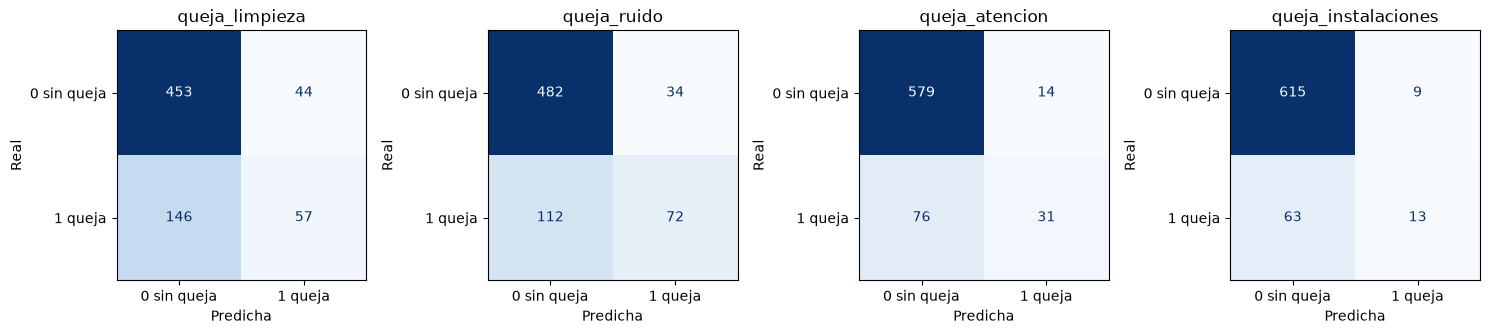

MODELO (a mano desde las matrices) · TEST · umbral 0,5


,precision,recall,especificidad,F1,soporte
queja_limpieza,0.564,0.281,0.911,0.375,203.0
queja_ruido,0.679,0.391,0.934,0.497,184.0
queja_atencion,0.689,0.290,0.976,0.408,107.0
queja_instalaciones,0.591,0.171,0.986,0.265,76.0


REFERENCIA (todo 0) · TEST


,precision,recall,especificidad,F1,soporte
queja_limpieza,0.0,0.0,1.0,0.0,203.0
queja_ruido,0.0,0.0,1.0,0.0,184.0
queja_atencion,0.0,0.0,1.0,0.0,107.0
queja_instalaciones,0.0,0.0,1.0,0.0,76.0


Las métricas a mano coinciden con scikit-learn.


In [55]:
# Una matriz de confusión binaria por etiqueta: [[TN, FP], [FN, TP]] con filas = real y columnas = predicha
mcm = multilabel_confusion_matrix(Yq_test, pred_q)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, m, e in zip(ax, mcm, ETIQUETAS):
    ConfusionMatrixDisplay(m, display_labels=["0 sin queja", "1 queja"]).plot(ax=a, cmap="Blues", values_format="d", colorbar=False)
    a.set_title(e); a.set_xlabel("Predicha"); a.set_ylabel("Real")
plt.tight_layout()
fig.savefig("figuras/quejas_matrices_por_etiqueta.png", dpi=200, bbox_inches="tight")
plt.show()

def metricas_por_etiqueta(Y_true, Y_pred):
    filas = {}
    for e, m in zip(ETIQUETAS, multilabel_confusion_matrix(Y_true, Y_pred)):
        tn, fp, fn, tp = m.ravel()
        pr = tp / (tp + fp) if tp + fp else 0.0
        rc = tp / (tp + fn)
        filas[e] = {"precision": pr, "recall": rc, "especificidad": tn / (tn + fp),
                    "F1": 2 * pr * rc / (pr + rc) if pr + rc else 0.0, "soporte": int(tp + fn)}
    return pd.DataFrame(filas).T

met_modelo = metricas_por_etiqueta(Yq_test, pred_q)
met_base = metricas_por_etiqueta(Yq_test, pred_base_q)
print("MODELO (a mano desde las matrices) · TEST · umbral 0,5")
display(met_modelo.round(3))
print("REFERENCIA (todo 0) · TEST")
display(met_base.round(3))

# Comprobación con scikit-learn
p_sk, r_sk, f_sk, _ = precision_recall_fscore_support(Yq_test, pred_q, zero_division=0)
assert np.allclose(met_modelo["precision"], p_sk) and np.allclose(met_modelo["recall"], r_sk) and np.allclose(met_modelo["F1"], f_sk)
print("Las métricas a mano coinciden con scikit-learn.")

Con el umbral 0,5 el modelo tiene una precisión razonable (0,56–0,69) y una especificidad alta (0,91–0,99), pero un recall bajo (0,17–0,39), es decir, se pierde la mayoría de las quejas. La etiqueta más difícil es instalaciones (recall 0,171 y F1 0,265), que es la menos frecuente, y la mejor es ruido (F1 0,497). La referencia tiene especificidad 1 y precision, recall y F1 de 0 en todas las etiquetas.

precision  recall     F1
Modelo (OvR + LR, umbral 0,5) macro         0.631   0.283  0.386
                              micro         0.631   0.304  0.410
                              weighted      0.628   0.304  0.406
Referencia (todo 0)           macro         0.000   0.000  0.000
                              micro         0.000   0.000  0.000
                              weighted      0.000   0.000  0.000

Pesos macro:     {'queja_limpieza': 0.25, 'queja_ruido': 0.25, 'queja_atencion': 0.25, 'queja_instalaciones': 0.25}
Pesos weighted:  {'queja_limpieza': 0.356, 'queja_ruido': 0.323, 'queja_atencion': 0.188, 'queja_instalaciones': 0.133}
Micro: no pondera por etiqueta; suma TP, FP y FN de todas las etiquetas antes de calcular.


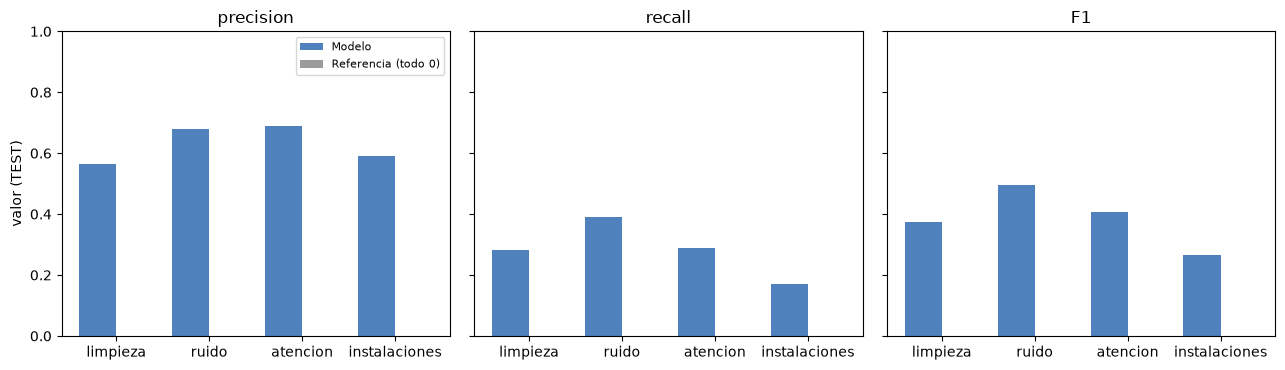

In [56]:
# Promedios macro, micro y weighted (precision, recall, F1) para modelo y referencia
def promedios_q(Y_true, Y_pred):
    out = {}
    for prom in ["macro", "micro", "weighted"]:
        p_, r_, f_, _ = precision_recall_fscore_support(Y_true, Y_pred, average=prom, zero_division=0)
        out[prom] = {"precision": p_, "recall": r_, "F1": f_}
    return pd.DataFrame(out).T

prom_modelo, prom_base = promedios_q(Yq_test, pred_q), promedios_q(Yq_test, pred_base_q)
tabla_q = pd.concat({"Modelo (OvR + LR, umbral 0,5)": prom_modelo, "Referencia (todo 0)": prom_base})
display(tabla_q.round(3))
tabla_q.round(4).to_csv("tablas/ej2b_promedios_modelo_vs_referencia.csv")

# Pesos de cada etiqueta
sop = Yq_test.sum().values
print("Pesos macro:    ", {e: 0.25 for e in ETIQUETAS})
print("Pesos weighted: ", {e: round(float(x), 3) for e, x in zip(ETIQUETAS, sop / sop.sum())})
print("Micro: no pondera por etiqueta; suma TP, FP y FN de todas las etiquetas antes de calcular.")

# Gráfico por etiqueta: modelo frente a referencia
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
x = np.arange(len(ETIQUETAS))
for a, m in zip(ax, ["precision", "recall", "F1"]):
    a.bar(x - 0.2, met_modelo[m], 0.4, label="Modelo", color="#4f81bd")
    a.bar(x + 0.2, met_base[m], 0.4, label="Referencia (todo 0)", color="#9b9b9b")
    a.set_xticks(x, [e.replace("queja_", "") for e in ETIQUETAS])
    a.set_title(m); a.set_ylim(0, 1)
ax[0].set_ylabel("valor (TEST)"); ax[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig("figuras/quejas_metricas_por_etiqueta.png", dpi=200, bbox_inches="tight")
plt.show()

Macro da el mismo peso (0,25) a cada etiqueta, así que instalaciones y atención influyen tanto como limpieza y ruido y el F1 macro baja (0,386). Weighted pondera por el soporte (0,356, 0,323, 0,188 y 0,133) y reduce la influencia de las raras. Micro suma TP, FP y FN de todas las etiquetas, por lo que mandan las frecuentes (F1 micro de 0,410). Por tanto, el peso de las etiquetas poco frecuentes es mayor en macro y menor en weighted y micro, y la macro es la que mejor deja ver el mal resultado en instalaciones.

### Apartado 12 · Acierto por decisión frente a exact match

In [57]:
# Dos medidas de acierto distintas
def acierto_decision(Y_true, Y_pred):
    """Decisiones (reseña, etiqueta) correctas sobre todas las parejas = 1 - Hamming loss."""
    return 1 - hamming_loss(Y_true, Y_pred)

def exact_match(Y_true, Y_pred):
    """Reseñas con las 4 etiquetas acertadas (accuracy_score sobre matrices multietiqueta)."""
    return accuracy_score(Y_true, Y_pred)

Yv_arr = Yq_test.values
acierto_m = (pred_q == Yv_arr).mean()                       # comprobación manual
exacto_m = (pred_q == Yv_arr).all(axis=1).mean()
assert np.isclose(acierto_m, acierto_decision(Yq_test, pred_q)) and np.isclose(exacto_m, exact_match(Yq_test, pred_q))

medidas = pd.DataFrame({
    "Modelo": [acierto_decision(Yq_test, pred_q), exact_match(Yq_test, pred_q), f1_score(Yq_test, pred_q, average="micro")],
    "Referencia (todo 0)": [acierto_decision(Yq_test, pred_base_q), exact_match(Yq_test, pred_base_q),
                            f1_score(Yq_test, pred_base_q, average="micro", zero_division=0)]},
    index=["Acierto por decisión (1 − Hamming loss)", "Exact match (conjunto completo de etiquetas)", "F1 micro"])
print(f"TEST · umbral 0,5. Proporción de reseñas sin quejas = {sin_quejas:.3f}")
display(medidas.round(3))
medidas.round(4).to_csv("tablas/ej2b_acierto_decision_vs_exact_match.csv")

TEST · umbral 0,5. Proporción de reseñas sin quejas = 0.409


,Modelo,Referencia (todo 0)
Acierto por decisión (1 − Hamming loss),0.822,0.796
Exact match (conjunto completo de etiquetas),0.456,0.414
F1 micro,0.410,0.000


Llamamos acierto por decisión a 1 − Hamming loss (proporción de las 700 × 4 parejas reseña–etiqueta bien decididas) y exact match a la proporción de reseñas con las cuatro etiquetas acertadas, que es lo que devuelve accuracy_score con matrices multietiqueta. El modelo obtiene 0,822 de acierto por decisión y 0,456 de exact match, y la referencia 0,796 y 0,414. La referencia acierta casi el 80 % de las decisiones porque la mayoría de las parejas son 0, y su exact match es justo la proporción de reseñas sin quejas, pero no detecta ninguna queja (recall 0 en todas).

### Comparación final

In [58]:
# Ejemplo de la comparación final: real [1, 0, 1, 0] y predicción [1, 0, 0, 0]
real = np.array([[1, 0, 1, 0]]); pred = np.array([[1, 0, 0, 0]])
print("Acierto por decisión (1 − Hamming loss):", 1 - hamming_loss(real, pred), "  (3 de 4 etiquetas bien)")
print("Exact match:", accuracy_score(real, pred), "  (el conjunto no es idéntico)")
print("F1 micro del ejemplo:", round(f1_score(real, pred, average="micro"), 3), "(TP=1, FP=0, FN=1)")

Acierto por decisión (1 − Hamming loss): 0.75   (3 de 4 etiquetas bien)
Exact match: 0.0   (el conjunto no es idéntico)
F1 micro del ejemplo: 0.667 (TP=1, FP=0, FN=1)


Con la salida real [1, 0, 1, 0] y la predicción [1, 0, 0, 0], el acierto por decisión es 3/4 = 0,75 y el exact match es 0, porque falla una etiqueta y el conjunto no coincide.

F1 micro y exact match no tienen por qué coincidir. El F1 micro cuenta TP, FP y FN de todas las decisiones e ignora los verdaderos negativos, mientras que el exact match exige acertar las cuatro etiquetas y cuenta como acierto una reseña sin quejas bien predicha. En test el exact match es 0,456 y el F1 micro 0,410, y en la referencia 0,414 frente a 0. En multiclase, en cambio, el F1 micro coincide con el accuracy porque cada reseña tiene una sola clase real y una predicha, y cada error es a la vez un FP y un FN.

La referencia de todo a 0 tiene muchos aciertos individuales porque la mayoría de las parejas reseña–etiqueta son 0, pero no detecta ninguna queja. Para detectar ese problema recomendamos mirar recall y F1 por etiqueta junto con el promedio macro, y comparar siempre con la referencia, además del acierto por decisión y el exact match.